# Importar datos :D

In [1]:
import pandas as pd
import openpyxl
import numpy as np
import missingno as msno
from functools import reduce
import hashlib
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import f_oneway
from datetime import date
import json

# configs para pandas
pd.set_option("display.max_rows", None)  # Show all rows
pd.set_option("display.max_columns", None)  # Show all columns
pd.set_option("display.width", 1000)

In [2]:
df_1 = pd.read_excel("data/raw/Totalizadores Planta - 2021_2023.xlsx", sheet_name=None)
df_2 = pd.read_excel("data/raw/Totalizadores Planta 2020_2022.xlsx", sheet_name=None)
df_3 = pd.read_excel("data/raw/Totalizadores Planta 2022_2023.xlsx", sheet_name=None)


In [11]:
# cambiar el df_n para ver los otros excel
i = 0
for k in df_1.values():
    i+=1
    print()
    print(f" ------------ {i} ---------------\n")
    lista = k.groupby(k['DIA'].dt.to_period('D'))['DIA'].count()
    for dia, cantidad in lista.items():
        if cantidad != 25:
            print(dia, cantidad)


 ------------ 1 ---------------

2021-07-01 23
2021-07-13 23
2021-09-30 50
2021-10-09 24
2021-11-01 23
2021-11-30 50
2022-02-28 100
2022-03-02 24
2022-03-05 24
2022-04-30 50
2022-06-30 51
2022-09-30 50
2022-11-30 50
2023-01-17 16
2023-02-28 99
2023-03-06 9

 ------------ 2 ---------------

2021-07-01 23
2021-07-13 23
2021-09-30 50
2021-10-09 24
2021-11-01 23
2021-11-30 50
2022-02-28 100
2022-03-02 24
2022-03-05 24
2022-04-30 50
2022-06-30 51
2022-09-30 50
2022-11-30 50
2023-01-17 16
2023-02-28 99
2023-03-06 9

 ------------ 3 ---------------

2021-07-01 23
2021-07-13 23
2021-09-30 50
2021-10-09 24
2021-11-01 23
2021-11-30 50
2022-02-28 100
2022-03-02 24
2022-03-05 24
2022-04-30 50
2022-06-30 51
2022-09-30 50
2022-11-30 50
2023-01-17 16
2023-02-28 99
2023-03-06 9

 ------------ 4 ---------------

2021-07-01 23
2021-07-13 23
2021-09-30 50
2021-10-09 24
2021-11-01 23
2021-11-30 50
2022-02-28 100
2022-03-02 24
2022-03-05 24
2022-04-30 50
2022-06-30 51
2022-09-30 50
2022-11-30 50
2023-01-1

In [30]:
print(df_1.keys())

dict_keys(['Consolidado KPI', 'Consolidado Produccion', 'Totalizadores Produccion', 'Consolidado EE', 'Totalizadores Energia', 'Consolidado Agua', 'Totalizadores Agua', 'Consolidado GasVapor', 'Totalizadores Gas y Vapor', 'Consolidado Aire', 'Totalizadores Aire', 'Totalizadores CO2', 'Totalizadores Efluentes', 'Totalizadores Glicol', 'Seguimiento Dia', 'Auxiliar'])


## La limpiada

In [3]:
archivos = {
    "2021_2023": df_1,
    "2020_2022": df_2,
    "2022_2023": df_3,
}

COL_FECHA = "fecha"

def limpiar(df):
    df = df.copy()
    df.columns = df.columns.astype(str).str.strip().str.lower()

    dia = pd.to_datetime(df["dia"], errors="coerce").dt.normalize()

    h = df["hora"]
    if pd.api.types.is_datetime64_any_dtype(h):
        h = h.dt.strftime("%H:%M:%S")
    hora = pd.to_timedelta(h.astype(str), errors="coerce")

    # quedarse solo con los cierres de día (23:30 en adelante)
    es_cierre = (hora >= pd.Timedelta(hours=23, minutes=30))
    df = df[es_cierre].copy()

    # fijar la marca de tiempo en 23:59:00 exactos
    df[COL_FECHA] = dia[es_cierre]     #.dt.date
    df = df.drop(columns=["dia", "hora"])
    df = df.dropna(subset=[COL_FECHA])
    df["_n"] = df.groupby(COL_FECHA).cumcount()   # orden de aparición de cada fecha repetida
    return df

def juntar_kpi(df, crit: str):
    """Suma todos los elementos de una columna de Consolidado KPI y sobreescribe el dato que estaba en esa columna a las 23:59"""
    df_t = df['Consolidado KPI'].copy()
    df_t.columns = df_t.columns.astype(str).str.strip().str.lower()

    # día y hora, con el mismo criterio que en limpiar()
    dia = pd.to_datetime(df_t['dia'], errors='coerce').dt.normalize()
    h = df_t['hora']
    if pd.api.types.is_datetime64_any_dtype(h):
        h = h.dt.strftime("%H:%M:%S")
    hora = pd.to_timedelta(h.astype(str), errors='coerce')

    es_cierre = (hora >= pd.Timedelta(hours=23, minutes=30)) & (hora < pd.Timedelta(days=1))

    for col in df_t.columns.drop(['dia', 'hora']):
        if not pd.api.types.is_numeric_dtype(df_t[col]):
            continue  # no tocar columnas de texto u otras no numéricas

        if crit == "sum":
            # suma de la columna en cada día, repetida en todas las filas de ese día
            suma_dia = df_t[col].groupby(dia).transform(lambda s: s.sum(min_count=1))
            df_t.loc[es_cierre, col] = suma_dia[es_cierre]
        if crit == "mean":
            media_dia = df_t[col].groupby(dia).transform('mean')
            df_t.loc[es_cierre, col] = media_dia[es_cierre]
        if crit == "median":
            mediana_dia = df_t[col].groupby(dia).transform('median')
            df_t.loc[es_cierre, col] = mediana_dia[es_cierre]

        # sobreescribir solo la fila de cierre
        

    df = df.copy()
    df['Consolidado KPI'] = df_t
    return df

def elegir_mas_similar(df):
    """Para cada fecha repetida calcula la desviación de cada fila contra el día anterior
    y el siguiente, se queda con la de menor desviación y borra las otras. Quita `_n`."""
    df = df.sort_values([COL_FECHA, "_n"]).reset_index(drop=True)
    num = df.select_dtypes("number").columns.drop(["_n", "id"], errors="ignore")
    escala = df[num].std().replace(0, np.nan)

    # valor típico de cada día; se desplaza para obtener el día anterior y el siguiente
    por_dia = df.groupby(COL_FECHA)[num].median()
    anterior = por_dia.shift(1).loc[df[COL_FECHA]].set_axis(df.index)
    siguiente = por_dia.shift(-1).loc[df[COL_FECHA]].set_axis(df.index)

    # desviación de cada fila (normalizada por columna, ignorando NaN)
    desv_ant = ((df[num] - anterior).abs() / escala).mean(axis=1, skipna=True)
    desv_sig = ((df[num] - siguiente).abs() / escala).mean(axis=1, skipna=True)
    desv = pd.concat([desv_ant, desv_sig], axis=1).mean(axis=1, skipna=True).fillna(np.inf)

    # por fecha, quedarse con la fila de menor desviación
    elegidas = desv.groupby(df[COL_FECHA]).idxmin()
    return df.loc[elegidas].drop(columns="_n").reset_index(drop=True)

def unir_hojas(dic):
    partes = []
    for hoja, df in dic.items():
        df = limpiar(df)
        n_antes = len(df)
        df = elegir_mas_similar(df).set_index(COL_FECHA)   # colapsa fechas repetidas dentro de la hoja
        if len(df) < n_antes:
            print(f"'{hoja}': {n_antes - len(df)} filas colapsadas por fecha repetida")
        partes.append(df)
    return reduce(lambda a, b: a.combine_first(b), partes)

# TODO usar esta para el preproccesing
def borrar_columnas_vacias(df, min=1100, umbral_varianza=10):
    """Elimina las columnas con varianza menor a umbral_varianza"""
    empty_columns = []

    for col in df.columns:
        if col == "fecha":
            continue

        nulos = df[col].isnull().sum()

        if pd.api.types.is_numeric_dtype(df[col]):
            varianza = df[col].var()
        else:
            varianza = None

        if nulos >= min or (
            varianza is not None
            and varianza <= umbral_varianza
        ):
            empty_columns.append(col)
            print(f"Eliminando columna: {col}")

    df.drop(columns=empty_columns, inplace=True)


trail = "mean" # <----- CAMBIAR ESTA VARIABLE POR sum, mean o median cambia la interpretación del conglomerado KPI
df_1 = juntar_kpi(df_1, crit= trail)
df_2 = juntar_kpi(df_2, crit= trail)
df_3 = juntar_kpi(df_3, crit= trail)
tot_1 = unir_hojas(df_1)
tot_2 = unir_hojas(df_2)
tot_3 = unir_hojas(df_3)

df_total = (
    reduce(lambda a, b: a.combine_first(b), [tot_1, tot_2, tot_3])
    .sort_index()
    .reset_index()
)

print(df_total.shape)
print(df_total[COL_FECHA].is_unique)   # debe dar True

borrar_columnas_vacias(df_total)

# AGREGAR LA VARIABLE OBJETIVO
df_total["frio_mañana (kw)"] = df_total["frio (kw)"].shift(-1)

'Consolidado KPI': 12 filas colapsadas por fecha repetida
'Consolidado Produccion': 12 filas colapsadas por fecha repetida
'Totalizadores Produccion': 12 filas colapsadas por fecha repetida
'Consolidado EE': 12 filas colapsadas por fecha repetida
'Totalizadores Energia': 12 filas colapsadas por fecha repetida
'Consolidado Agua': 12 filas colapsadas por fecha repetida
'Totalizadores Agua': 12 filas colapsadas por fecha repetida
'Consolidado GasVapor': 12 filas colapsadas por fecha repetida
'Totalizadores Gas y Vapor': 12 filas colapsadas por fecha repetida
'Consolidado Aire': 12 filas colapsadas por fecha repetida
'Totalizadores Aire': 12 filas colapsadas por fecha repetida
'Totalizadores CO2': 13 filas colapsadas por fecha repetida
'Totalizadores Efluentes': 12 filas colapsadas por fecha repetida
'Totalizadores Glicol': 12 filas colapsadas por fecha repetida
'Seguimiento Dia': 12 filas colapsadas por fecha repetida
'Auxiliar': 12 filas colapsadas por fecha repetida
'Consolidado KPI': 1

C:\Users\Arturo\AppData\Local\Temp\ipykernel_8724\2240455351.py:136: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  .reset_index()
C:\Users\Arturo\AppData\Local\Temp\ipykernel_8724\2240455351.py:145: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_total["frio_mañana (kw)"] = df_total["frio (kw)"].shift(-1)


Para juntar el conglomerado KPI elegímos la media como método porque fue la unica de las tres formas que probamos que nos dio tres variables nuevas en las 15 más correlacionadas con frío de mañana

In [4]:
columnas_object = df_total.select_dtypes(include="object").columns

for col in columnas_object:
    numericos = pd.to_numeric(df_total[col], errors="coerce")

    validos = numericos.dropna()

    if (validos % 1 == 0).all():
        df_total[col] = numericos.astype("Int64")
    else:
        df_total[col] = numericos.astype("float64")

print(df_total.dtypes)

fecha                              datetime64[us]
ee planta / hl                            float64
ee envasado / hl                          float64
ee linea 2 / hl                           float64
ee linea 3 / hl                           float64
ee linea 4 / hl                           float64
ee servicios / hl                         float64
ee sala maq / hl                          float64
ee frio / hl                              float64
ee agua / hl                              float64
ee resto serv / hl                        float64
ee resto planta / hl                      float64
agua planta / hl                          float64
agua cocina / hl                          float64
agua linea 2/hl                           float64
agua linea 3/hl                           float64
agua linea 5/hl                           float64
agua servicios/hl                         float64
agua planta de agua/hl                    float64
produccion agua / hl                      float64


In [5]:
varianzas = df_total.select_dtypes(include="number").var()

print(f"Varianza promedio: {varianzas.mean():.4f}")

display(varianzas.sort_values().to_frame("Varianza"))

Varianza promedio: 14680825400495425536.0000


,Varianza
aire l4 / hl,1.143790e+01
agua servicios/hl,1.202414e+01
ee agua / hl,1.211272e+01
ee linea 3 / hl,1.334181e+01
aire l3 / hl,1.589209e+01
aire servicios / hl,1.909972e+01
agua cocina / hl,2.180779e+01
temp tq intermedio,2.349751e+01
meta et envasado,2.416705e+01
red administracion,2.721434e+01


In [6]:
df_total.to_excel("data/clean/df_total.xlsx", index=False)

# Versionado

In [7]:
REGISTRY_PATH = Path("data/logs/data_log.json")

def huella(ruta: Path, algoritmo: str = "sha256", bloque: int = 1 << 20) -> str:
    """Devuelve el resumen hexadecimal del archivo, leyendolo de a 1 MiB."""
    h = hashlib.new(algoritmo)
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()


def load_registry() -> list:
    if REGISTRY_PATH.exists():
        with open(REGISTRY_PATH, encoding="utf-8") as f:
            return json.load(f)
    return []


def save_registry(registry: list) -> None:
    with open(REGISTRY_PATH, "w", encoding="utf-8") as f:
        json.dump(registry, f, indent=2, ensure_ascii=False)


def register_version(ruta: Path, transformations: list) -> None:
    """Registra una nueva versión solo si abalone_clean.csv cambió."""
    registry = load_registry()
    new_hash = huella(ruta)

    # Si el hash es igual al de la última versión, no hubo cambios reales
    if registry and registry[-1]["sha256"] == new_hash:
        print(
            f"Sin cambios (hash {new_hash[:12]}...): no se crea nueva versión.")
        return

    entry = {
        "version": f"v{len(registry) + 1}",
        "created_at": date.today().isoformat(),
        "output": str(ruta).replace("\\", "/"),
        "sha256": new_hash,
        "parent_sha256": registry[-1]["sha256"] if registry else None,
        "transformations": transformations,
        "comments": str(input("ingrese un comentario para el json del dataframe: "))
    }
    registry.append(entry)
    save_registry(registry)

    print(f"Nueva versión registrada: {entry['version']} ({new_hash[:12]}...)")


In [8]:
transformations = []
transformations.append(f"Definimos quedarnos con la media como método para juntar los datos de conglomerado KPI")
register_version(Path("data/clean/df_total.xlsx"),transformations)

Nueva versión registrada: v5 (18830c0640cd...)


# Análisis

In [7]:
print(df_total.shape)

(1185, 321)


In [8]:
resumen = pd.DataFrame({
    "Tipo de dato": df_total.dtypes,
    "Valores no nulos": df_total.count(),
    "Valores nulos": df_total.isnull().sum(),
    "Mínimo": df_total.min(numeric_only=True),
    "Máximo": df_total.max(numeric_only=True)
})

display(resumen)

,Tipo de dato,Valores no nulos,Valores nulos,Mínimo,Máximo
,float64,1184,1,4.419800e+05,4.540700e+05
(vapor olla 2 (ton),float64,1185,0,0.000000e+00,1.580000e+02
.1,float64,1184,1,4.419710e+05,4.540710e+05
agua bodega (hl),float64,1185,0,1.015000e+03,1.597800e+04
agua bodega / hl,float64,1164,21,0.000000e+00,9.197801e+02
agua cald,float64,1185,0,0.000000e+00,2.031000e+02
agua calderas,float64,827,358,0.000000e+00,1.830000e+02
agua cist industrial,float64,1185,0,0.000000e+00,1.241300e+03
agua co2,float64,827,358,1.640000e+01,3.941000e+02
agua cocina (hl),float64,1185,0,0.000000e+00,1.400140e+04


In [9]:
columnas_numericas = df_total.select_dtypes(include="number").columns

for col in columnas_numericas:
    negativos = df_total[df_total[col] < 0]
    enormes = df_total[df_total[col].abs() >= 1_000_000]

    if not negativos.empty or not enormes.empty:
        print(f"\n--- {col} ---")

        if not negativos.empty:
            print(f"Valores negativos: {len(negativos)}")
            print(negativos[["fecha", col]].head(10))

        if not enormes.empty:
            print(f"Valores del orden de millones: {len(enormes)}")
            print(enormes[["fecha", col]].head(10))


--- ee planta / hl ---
Valores negativos: 1
         fecha  ee planta / hl
651 2022-04-28      -25.420688

--- ee elaboracion / hl ---
Valores negativos: 1
         fecha  ee elaboracion / hl
936 2023-02-13           -40.920292

--- ee bodega / hl ---
Valores negativos: 4
          fecha  ee bodega / hl
382  2021-07-26       -8.484795
387  2021-07-31      -10.133118
936  2023-02-13      -73.781201
1138 2023-09-09     -418.753161

--- ee envasado / hl ---
Valores del orden de millones: 3
          fecha  ee envasado / hl
385  2021-07-29      3.476284e+12
462  2021-10-17      3.234176e+13
1041 2023-06-02      1.314824e+13

--- ee linea 2 / hl ---
Valores negativos: 3
         fecha  ee linea 2 / hl
527 2021-12-22        -1.526343
895 2023-01-03        -1.938545
896 2023-01-04        -1.295797

--- ee servicios / hl ---
Valores negativos: 1
         fecha  ee servicios / hl
651 2022-04-28        -107.040402

--- ee sala maq / hl ---
Valores negativos: 1
         fecha  ee sala maq / hl
6

Ver lo de los valores negativos que no tienen sentido.

## Outliers

In [23]:
objetivo = "frio_mañana (kw)"

correlaciones = df_total.select_dtypes(include="number").corr()[objetivo]

columnas_correlacionadas = correlaciones[
    (correlaciones > 0.6) | (correlaciones < -0.6)
].index.tolist()

columnas_correlacionadas.remove(objetivo)

print("Columnas con correlación absoluta mayor a 0,6:")
print(columnas_correlacionadas)
print(len(columnas_correlacionadas))

Columnas con correlación absoluta mayor a 0,6:
['meta et planta', 'meta et envasado', 'servicios (kw)', 'frio (kw)', 'kw trafo 11', 'kw trafo 10', 'kw cond 5. 6 y 9', 'agua planta (hl)', 'planta de agua (hl)', 'produccion (hl)']
10


In [25]:
def detectar_outliers(df, variable_univariada, plot=True):

    serie = pd.to_numeric(df[variable_univariada], errors="coerce")

    # =========================
    # MÉTODO IQR
    # =========================
    Q1 = serie.quantile(0.25)
    Q3 = serie.quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior_iqr = Q1 - 1.5 * IQR
    limite_superior_iqr = Q3 + 1.5 * IQR

    mascara_iqr = (
        (serie < limite_inferior_iqr) |
        (serie > limite_superior_iqr)
    )

    outliers_iqr = df[mascara_iqr.fillna(False)]

    print(f"Variable: {variable_univariada}")
    print("\n--- Método IQR ---")
    print(f"Q1: {Q1:.2f} | Q3: {Q3:.2f} | IQR: {IQR:.2f}")
    print(f"Rango no atípico: [{limite_inferior_iqr:.2f}, {limite_superior_iqr:.2f}]")
    print(f"Cantidad de outliers detectados: {len(outliers_iqr)}")

    # =========================
    # Z-SCORE MODIFICADO
    # =========================
    serie_valida = serie.dropna()

    median = serie_valida.median()
    mad = np.median(np.abs(serie_valida - median))
    constante_mad = 0.6745

    limite_inferior_zmod = np.nan
    limite_superior_zmod = np.nan

    print("\n--- Método Z-Score Modificado ---")
    print(f"Mediana: {median:.2f} | MAD: {mad:.4f}")

    if mad == 0:
        print("No se puede aplicar el método: MAD = 0.")
        outliers_zmod = df.iloc[0:0]
    else:
        modified_z_scores = (
            constante_mad * (serie - median) / mad
        )

        mascara_zmod = modified_z_scores.abs() > 3.5
        outliers_zmod = df[mascara_zmod.fillna(False)]

        limite_inferior_zmod = median - (3.5 * mad / constante_mad)
        limite_superior_zmod = median + (3.5 * mad / constante_mad)

    print(
        f"Rango no atípico: "
        f"[{limite_inferior_zmod:.2f}, {limite_superior_zmod:.2f}]"
    )
    print(f"Cantidad de outliers detectados: {len(outliers_zmod)}")

    # =========================
    # MÉTODO DE PERCENTILES
    # =========================
    p1 = serie.quantile(0.01)
    p99 = serie.quantile(0.99)

    mascara_percentil = (serie < p1) | (serie > p99)
    outliers_percentil = df[mascara_percentil.fillna(False)]

    print("\n--- Método Percentiles Extremos ---")
    print(f"Percentil 1: {p1:.2f} | Percentil 99: {p99:.2f}")
    print(f"Rango no atípico: [{p1:.2f}, {p99:.2f}]")
    print(f"Cantidad de outliers detectados: {len(outliers_percentil)}")

    # =========================
    # GRÁFICOS
    # =========================
    if plot:
        plt.close("all")
        fig, axes = plt.subplots(1, 3, figsize=(20, 5))

        # IQR
        sns.boxplot(x=serie.dropna(), ax=axes[0], color="skyblue")
        axes[0].set_title(
            f"Método IQR: {len(outliers_iqr)} outliers\n"
            f"Rango: [{limite_inferior_iqr:.2f}, {limite_superior_iqr:.2f}]"
        )
        axes[0].set_xlabel(variable_univariada)

        # Z-Score modificado
        sns.histplot(serie.dropna(), kde=True, ax=axes[1], color="steelblue")

        if len(outliers_zmod) > 0:
            valores_zmod = serie.loc[outliers_zmod.index]
            axes[1].scatter(
                valores_zmod,
                np.zeros(len(valores_zmod)),
                color="red",
                label="Outliers Z-Modificado",
                zorder=5
            )
            axes[1].legend()

        axes[1].set_title(
            f"Z-Score Modificado: {len(outliers_zmod)} outliers\n"
            f"Rango: [{limite_inferior_zmod:.2f}, {limite_superior_zmod:.2f}]"
        )
        axes[1].set_xlabel(variable_univariada)
        axes[1].set_ylabel("Frecuencia")

        # Percentiles
        sns.histplot(serie.dropna(), kde=True, ax=axes[2], color="steelblue")

        xmin = serie.min()
        xmax = serie.max()

        if pd.notna(p1) and pd.notna(p99):
            axes[2].axvspan(
                xmin, p1, color="red", alpha=0.15,
                label="Zona atípica inferior"
            )
            axes[2].axvspan(
                p99, xmax, color="red", alpha=0.15,
                label="Zona atípica superior"
            )
            axes[2].axvline(
                p1, color="gray", linestyle="--",
                label=f"Percentil 1 ({p1:.2f})"
            )
            axes[2].axvline(
                p99, color="gray", linestyle="--",
                label=f"Percentil 99 ({p99:.2f})"
            )

        axes[2].set_title(
            f"Percentiles extremos: {len(outliers_percentil)} outliers\n"
            f"Rango: [{p1:.2f}, {p99:.2f}]"
        )
        axes[2].set_xlabel(variable_univariada)
        axes[2].set_ylabel("Frecuencia")
        axes[2].legend()

        plt.tight_layout()
        plt.show()

    return outliers_iqr, outliers_zmod, outliers_percentil

10 features mas correlacionadas

Variable: meta et planta

--- Método IQR ---
Q1: 59.00 | Q3: 68.00 | IQR: 9.00
Rango no atípico: [45.50, 81.50]
Cantidad de outliers detectados: 90

--- Método Z-Score Modificado ---
Mediana: 60.38 | MAD: 2.3800
Rango no atípico: [48.03, 72.73]
Cantidad de outliers detectados: 121

--- Método Percentiles Extremos ---
Percentil 1: 57.00 | Percentil 99: 84.00
Rango no atípico: [57.00, 84.00]
Cantidad de outliers detectados: 0


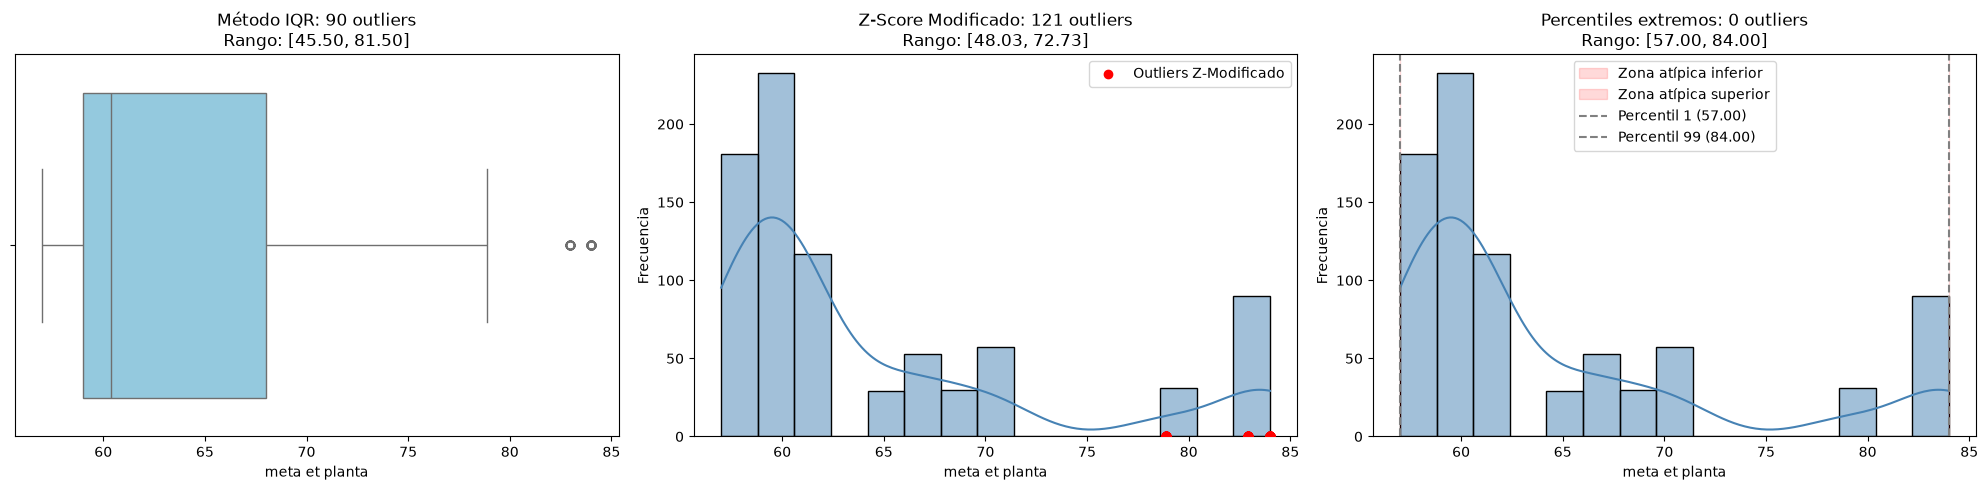

Variable: meta et envasado

--- Método IQR ---
Q1: 34.77 | Q3: 40.08 | IQR: 5.30
Rango no atípico: [26.82, 48.04]
Cantidad de outliers detectados: 90

--- Método Z-Score Modificado ---
Mediana: 35.59 | MAD: 1.4028
Rango no atípico: [28.31, 42.87]
Cantidad de outliers detectados: 121

--- Método Percentiles Extremos ---
Percentil 1: 33.60 | Percentil 99: 49.51
Rango no atípico: [33.60, 49.51]
Cantidad de outliers detectados: 0


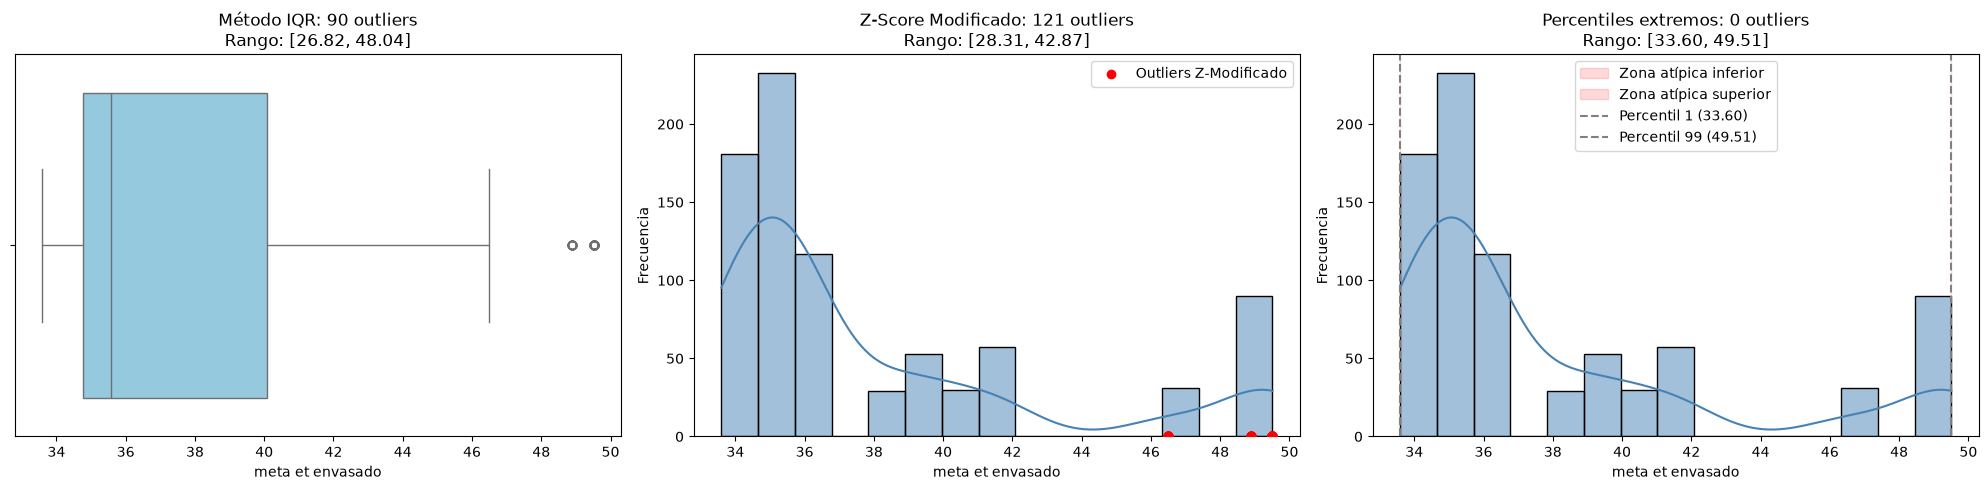

Variable: servicios (kw)

--- Método IQR ---
Q1: 31399.00 | Q3: 46293.00 | IQR: 14894.00
Rango no atípico: [9058.00, 68634.00]
Cantidad de outliers detectados: 2

--- Método Z-Score Modificado ---
Mediana: 39052.00 | MAD: 7416.0000
Rango no atípico: [570.16, 77533.84]
Cantidad de outliers detectados: 0

--- Método Percentiles Extremos ---
Percentil 1: 15387.24 | Percentil 99: 58062.18
Rango no atípico: [15387.24, 58062.18]
Cantidad de outliers detectados: 24


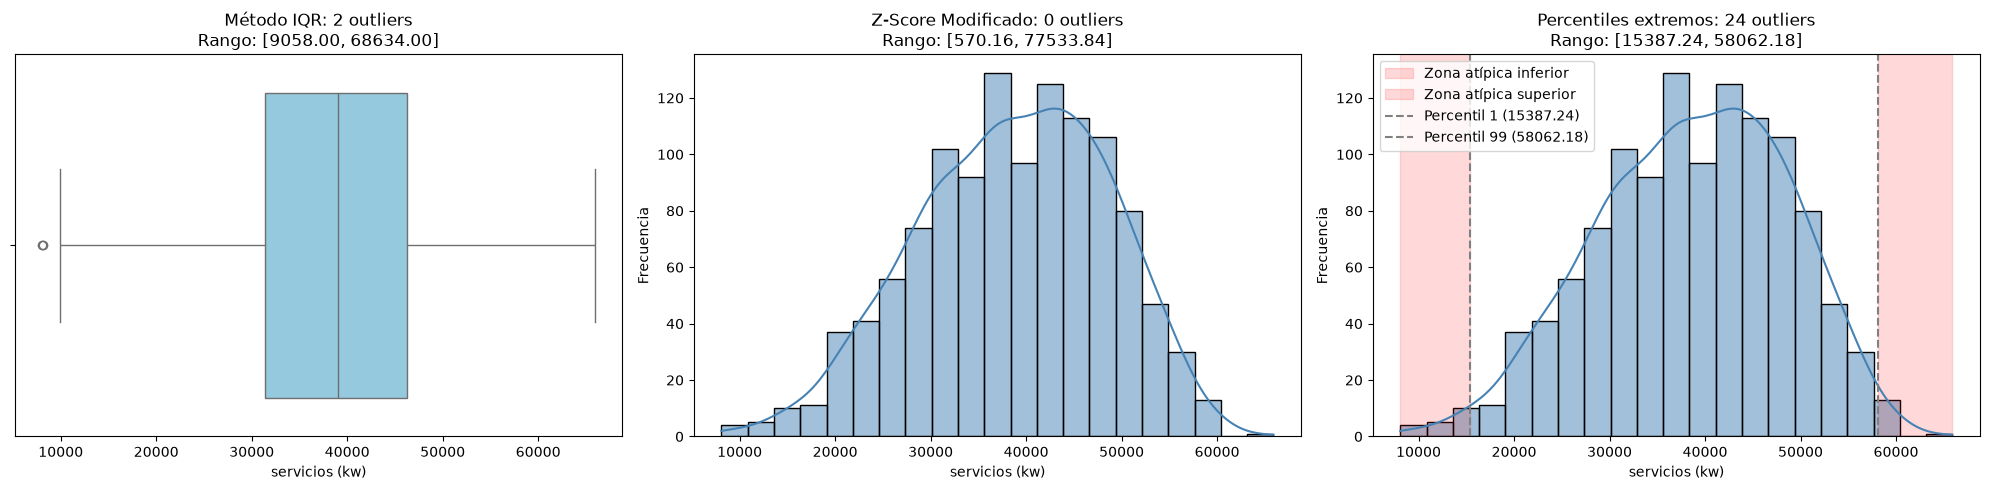

Variable: frio (kw)

--- Método IQR ---
Q1: 17942.00 | Q3: 29257.00 | IQR: 11315.00
Rango no atípico: [969.50, 46229.50]
Cantidad de outliers detectados: 3

--- Método Z-Score Modificado ---
Mediana: 23689.00 | MAD: 5691.0000
Rango no atípico: [-5841.76, 53219.76]
Cantidad de outliers detectados: 2

--- Método Percentiles Extremos ---
Percentil 1: 7298.20 | Percentil 99: 40912.04
Rango no atípico: [7298.20, 40912.04]
Cantidad de outliers detectados: 24


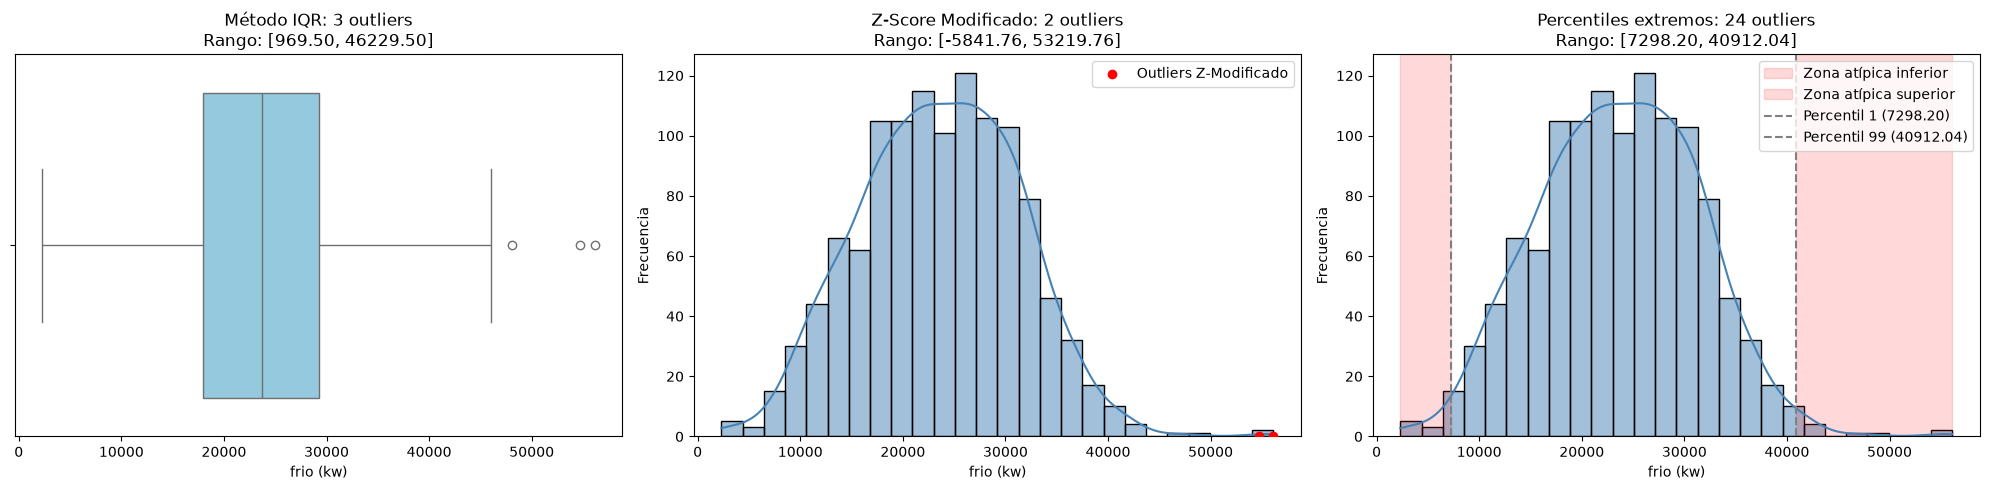

Variable: kw trafo 11

--- Método IQR ---
Q1: 13480.00 | Q3: 21512.00 | IQR: 8032.00
Rango no atípico: [1432.00, 33560.00]
Cantidad de outliers detectados: 7

--- Método Z-Score Modificado ---
Mediana: 18452.00 | MAD: 3772.0000
Rango no atípico: [-1121.02, 38025.02]
Cantidad de outliers detectados: 0

--- Método Percentiles Extremos ---
Percentil 1: 3797.60 | Percentil 99: 26814.08
Rango no atípico: [3797.60, 26814.08]
Cantidad de outliers detectados: 24


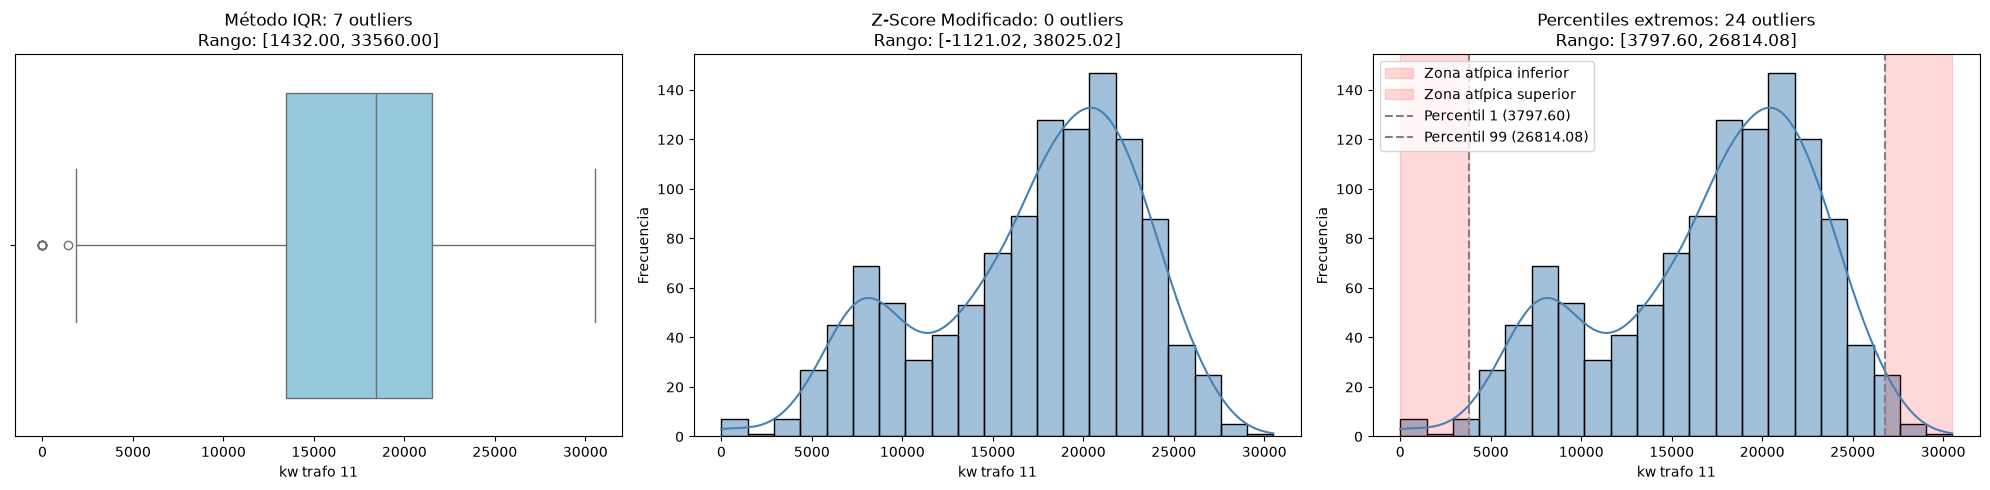

Variable: kw trafo 10

--- Método IQR ---
Q1: 8656.00 | Q3: 11524.25 | IQR: 2868.25
Rango no atípico: [4353.62, 15826.62]
Cantidad de outliers detectados: 9

--- Método Z-Score Modificado ---
Mediana: 10258.00 | MAD: 1407.0000
Rango no atípico: [2957.04, 17558.96]
Cantidad de outliers detectados: 2

--- Método Percentiles Extremos ---
Percentil 1: 4601.02 | Percentil 99: 13849.90
Rango no atípico: [4601.02, 13849.90]
Cantidad de outliers detectados: 24


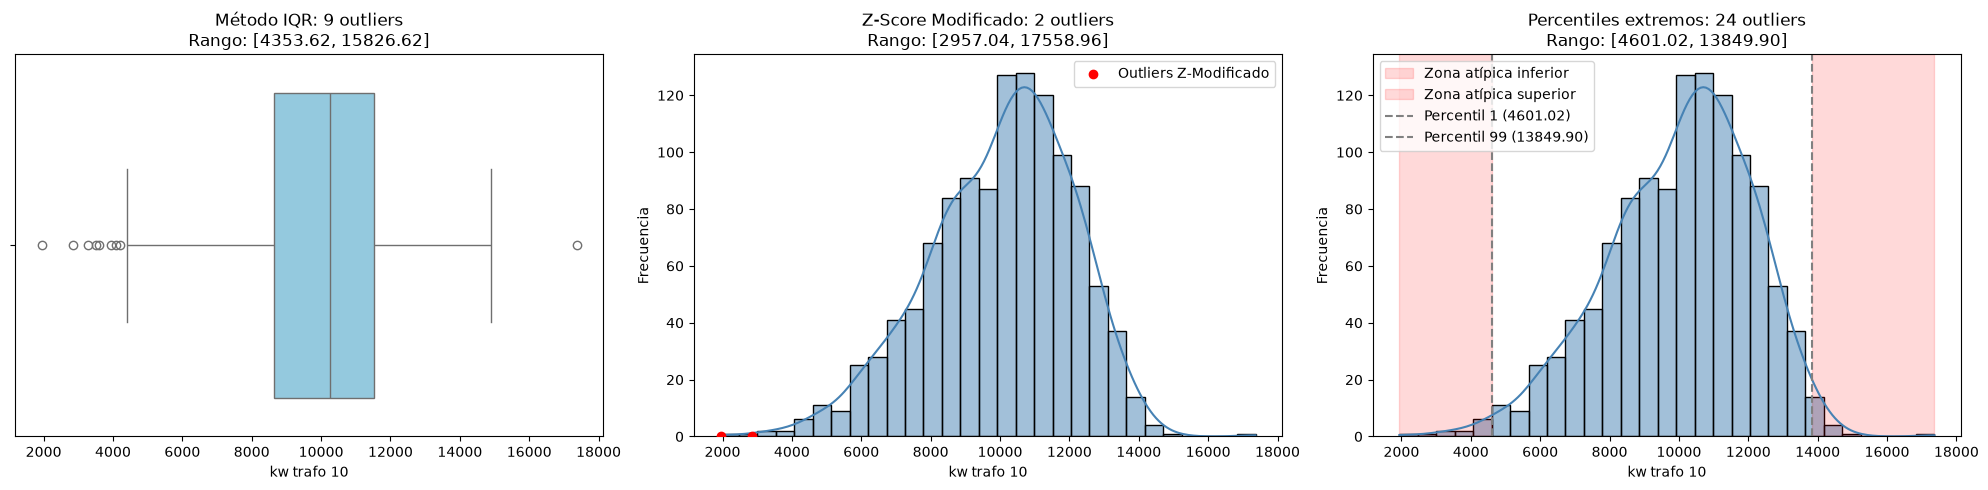

Variable: kw cond 5. 6 y 9

--- Método IQR ---
Q1: 330.00 | Q3: 1050.00 | IQR: 720.00
Rango no atípico: [-750.00, 2130.00]
Cantidad de outliers detectados: 0

--- Método Z-Score Modificado ---
Mediana: 556.00 | MAD: 380.0000
Rango no atípico: [-1415.83, 2527.83]
Cantidad de outliers detectados: 0

--- Método Percentiles Extremos ---
Percentil 1: 0.00 | Percentil 99: 1189.00
Rango no atípico: [0.00, 1189.00]
Cantidad de outliers detectados: 11


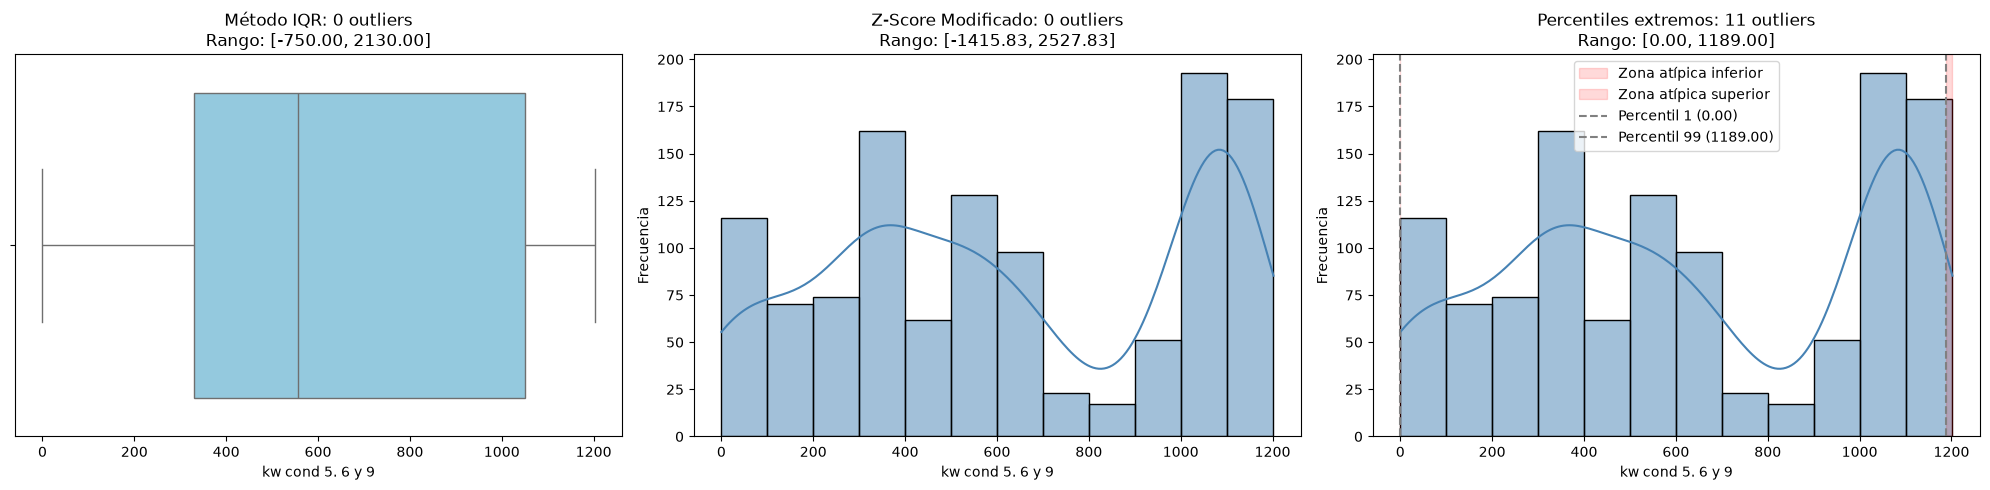

Variable: agua planta (hl)

--- Método IQR ---
Q1: 26570.00 | Q3: 38486.80 | IQR: 11916.80
Rango no atípico: [8694.80, 56362.00]
Cantidad de outliers detectados: 9

--- Método Z-Score Modificado ---
Mediana: 33442.20 | MAD: 5773.2000
Rango no atípico: [3484.90, 63399.50]
Cantidad de outliers detectados: 0

--- Método Percentiles Extremos ---
Percentil 1: 9455.80 | Percentil 99: 47510.56
Rango no atípico: [9455.80, 47510.56]
Cantidad de outliers detectados: 24


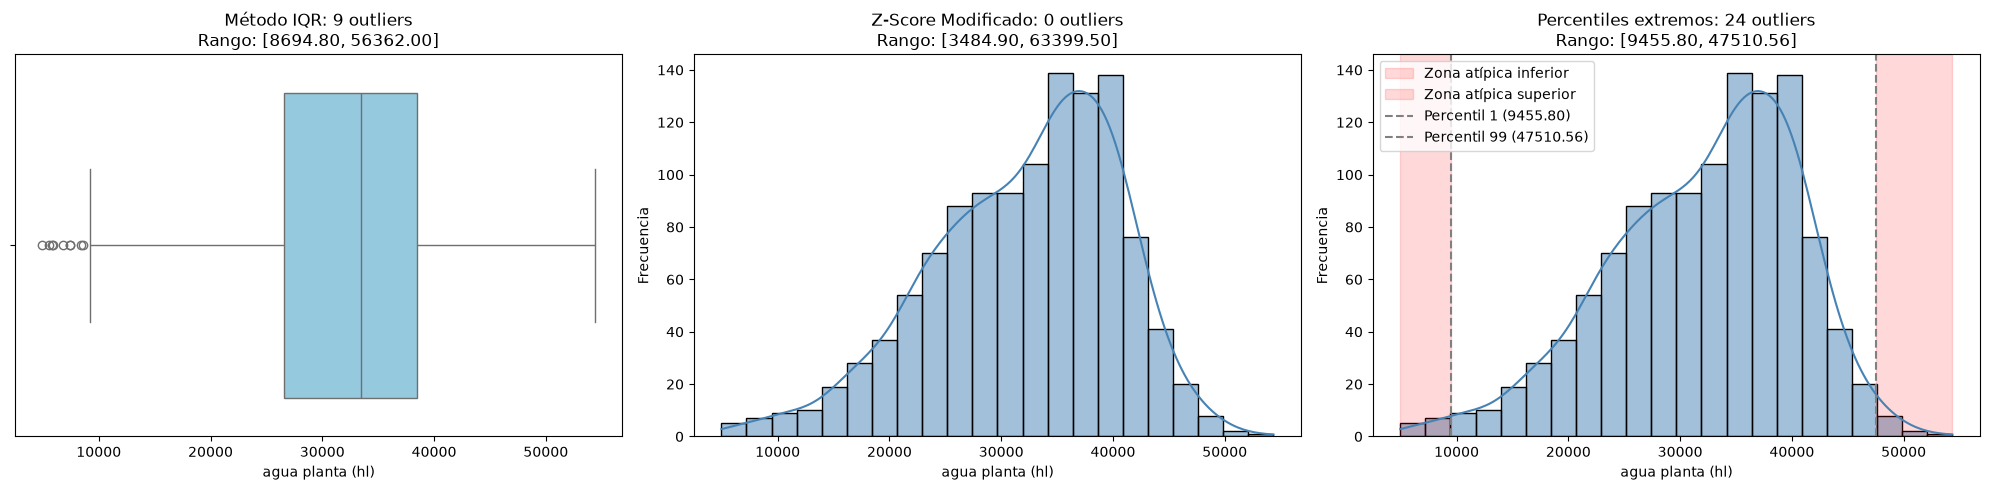

Variable: planta de agua (hl)

--- Método IQR ---
Q1: 30885.80 | Q3: 47956.20 | IQR: 17070.40
Rango no atípico: [5280.20, 73561.80]
Cantidad de outliers detectados: 1

--- Método Z-Score Modificado ---
Mediana: 41185.09 | MAD: 8167.9100
Rango no atípico: [-1198.43, 83568.61]
Cantidad de outliers detectados: 0

--- Método Percentiles Extremos ---
Percentil 1: 10107.82 | Percentil 99: 60697.30
Rango no atípico: [10107.82, 60697.30]
Cantidad de outliers detectados: 24


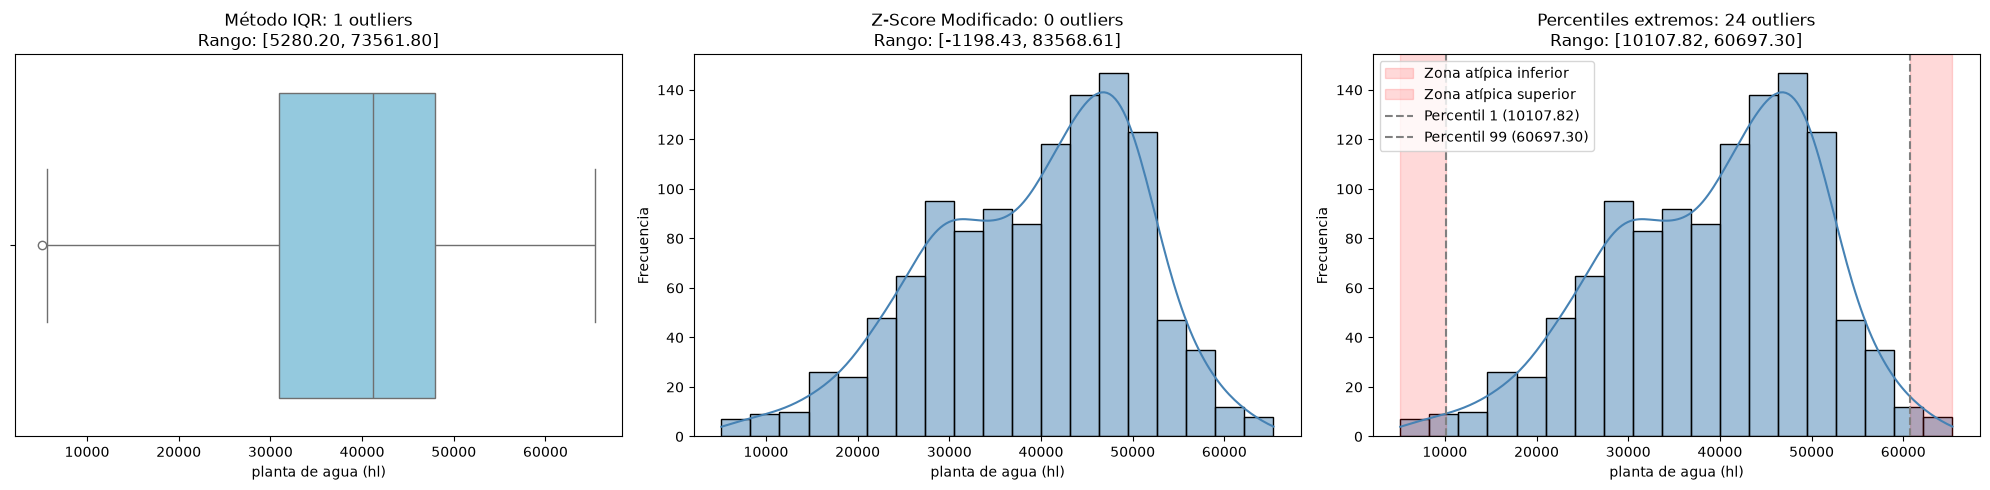

Variable: produccion (hl)

--- Método IQR ---
Q1: 19550.70 | Q3: 29948.60 | IQR: 10397.90
Rango no atípico: [3953.85, 45545.45]
Cantidad de outliers detectados: 11

--- Método Z-Score Modificado ---
Mediana: 25574.50 | MAD: 5049.8000
Rango no atípico: [-629.06, 51778.06]
Cantidad de outliers detectados: 0

--- Método Percentiles Extremos ---
Percentil 1: 4499.48 | Percentil 99: 37379.04
Rango no atípico: [4499.48, 37379.04]
Cantidad de outliers detectados: 24


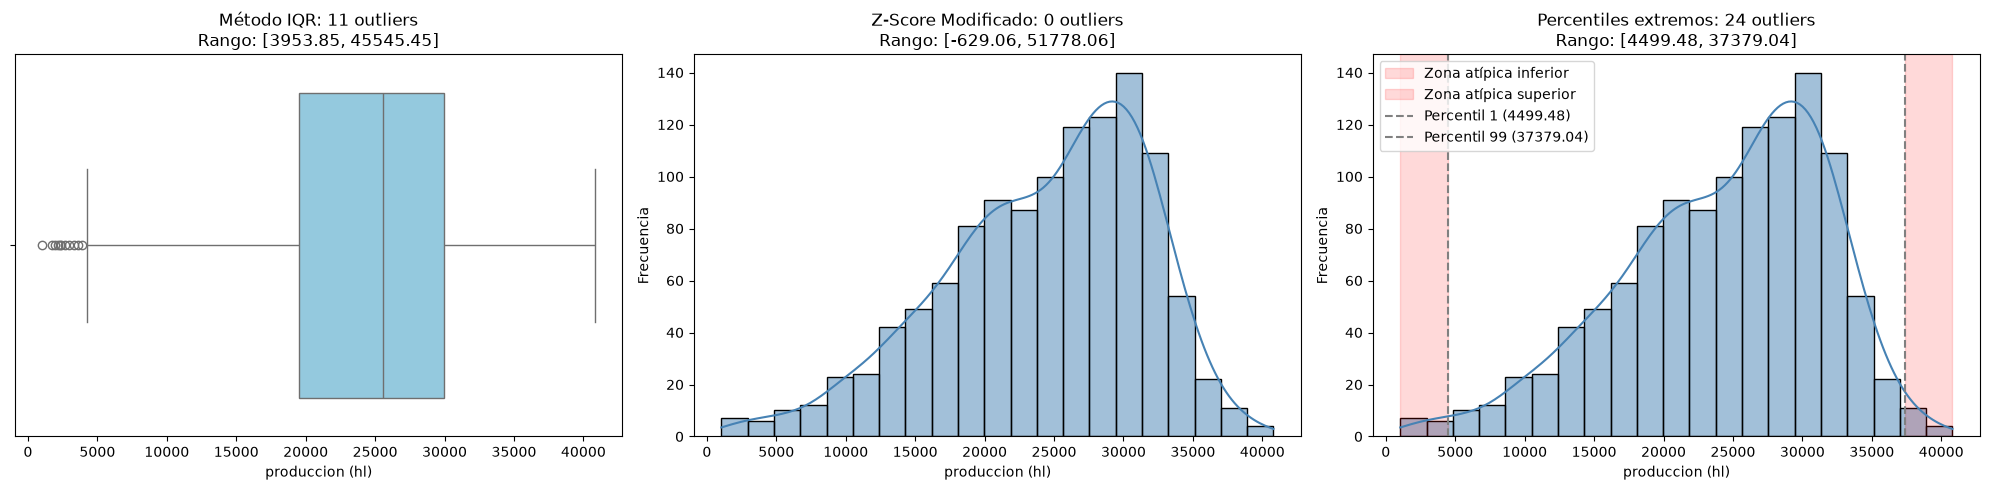

In [26]:
for n in range(len(columnas_correlacionadas)):
    detectar_outliers(df_total, columnas_correlacionadas[n])

10 features con mayor varianza

In [ ]:
features_mayor_varianza = varianzas.nlargest(10).index.tolist()
print(features_mayor_varianza)

['vapor de caldera 4 kg', 'sala maq (kw)', 'kw comp kaeser', 'gas planta (mj)', 'restos planta (kw)', 'totalizador bba envasado', 'envasado (kw)', 'kw linea 2', 'et envasado (mj)', 'et elaboracion (mj)']


Variable: vapor de caldera 4 kg

--- Método IQR ---
Q1: 0.00 | Q3: 84190.00 | IQR: 84190.00
Rango no atípico: [-126285.00, 210475.00]
Cantidad de outliers detectados: 3

--- Método Z-Score Modificado ---
Mediana: 0.00 | MAD: 0.0000
No se puede aplicar el método: MAD = 0.
Rango no atípico: [nan, nan]
Cantidad de outliers detectados: 0

--- Método Percentiles Extremos ---
Percentil 1: 0.00 | Percentil 99: 202034.00
Rango no atípico: [0.00, 202034.00]
Cantidad de outliers detectados: 13


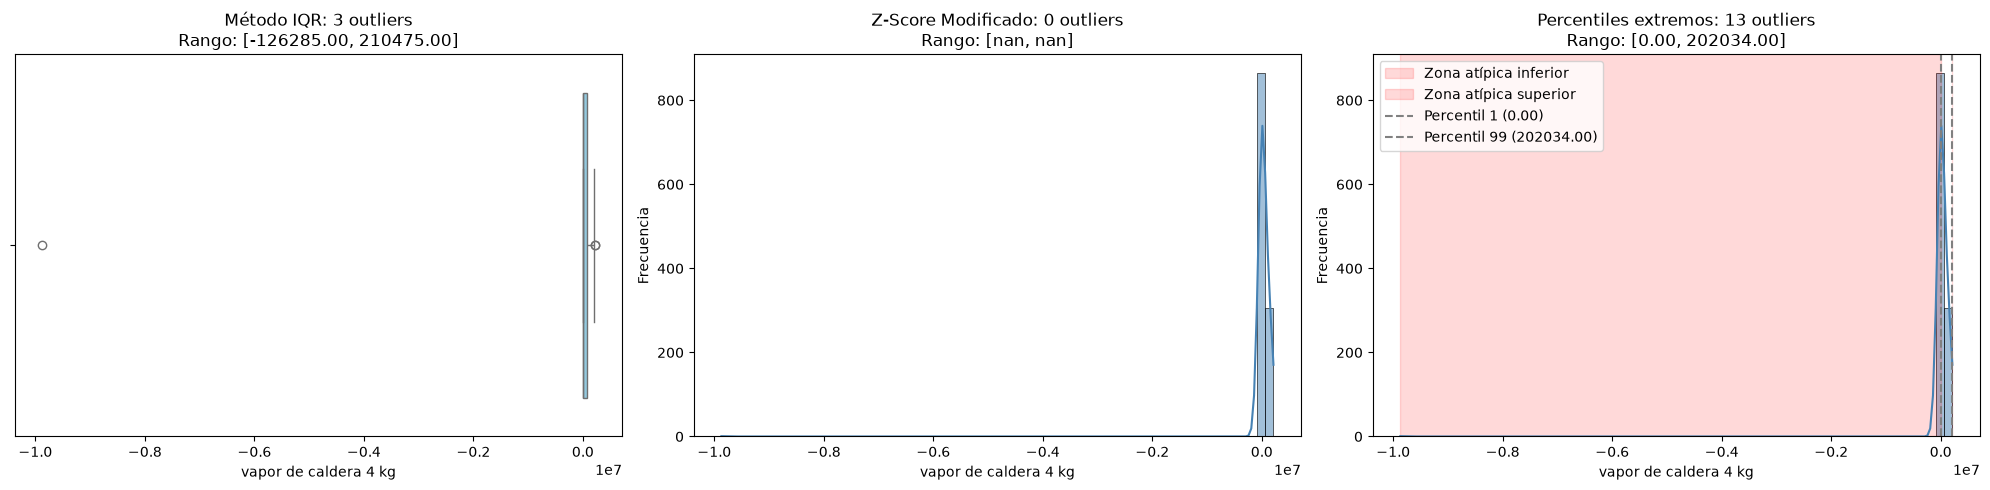

Variable: sala maq (kw)

--- Método IQR ---
Q1: 20872.00 | Q3: 32751.00 | IQR: 11879.00
Rango no atípico: [3053.50, 50569.50]
Cantidad de outliers detectados: 11

--- Método Z-Score Modificado ---
Mediana: 26875.00 | MAD: 5963.0000
Rango no atípico: [-4067.18, 57817.18]
Cantidad de outliers detectados: 7

--- Método Percentiles Extremos ---
Percentil 1: 10046.44 | Percentil 99: 46659.60
Rango no atípico: [10046.44, 46659.60]
Cantidad de outliers detectados: 24


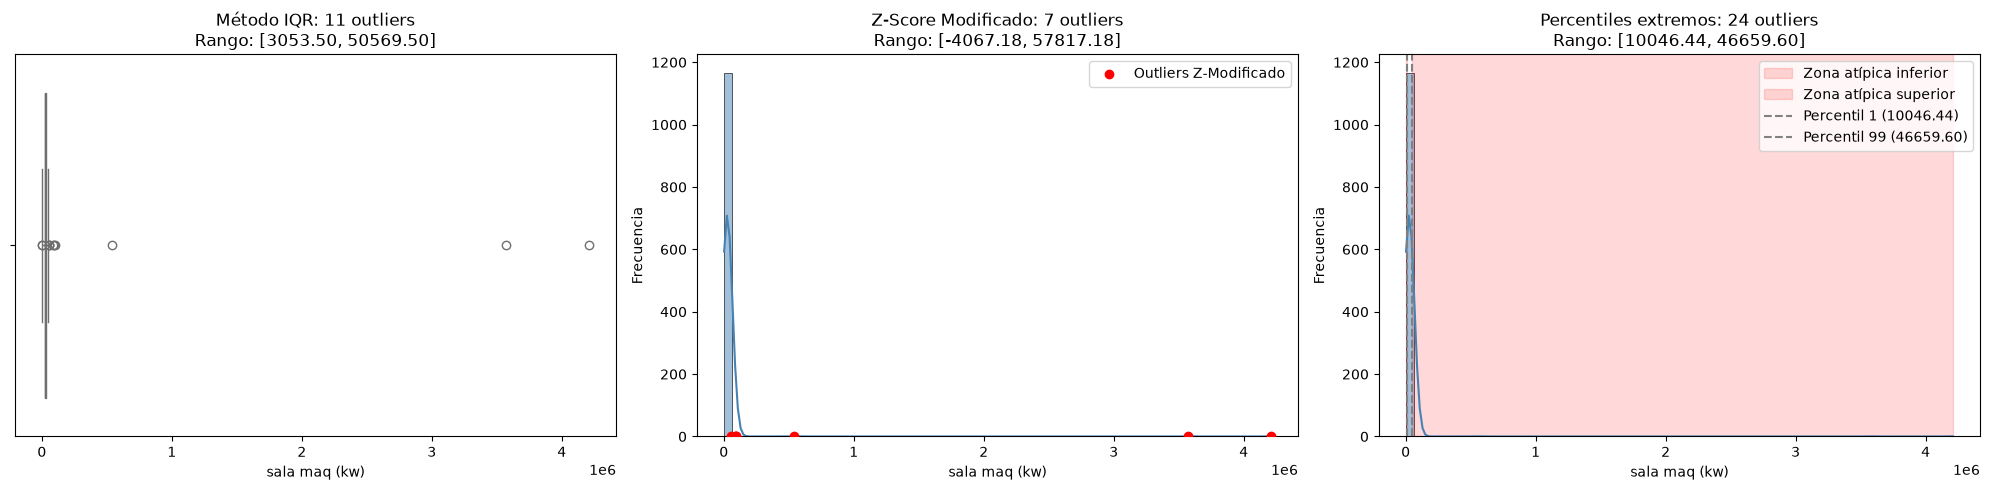

Variable: kw comp kaeser

--- Método IQR ---
Q1: 1681.00 | Q3: 2851.00 | IQR: 1170.00
Rango no atípico: [-74.00, 4606.00]
Cantidad de outliers detectados: 7

--- Método Z-Score Modificado ---
Mediana: 2382.00 | MAD: 495.0000
Rango no atípico: [-186.57, 4950.57]
Cantidad de outliers detectados: 5

--- Método Percentiles Extremos ---
Percentil 1: 0.00 | Percentil 99: 2998.28
Rango no atípico: [0.00, 2998.28]
Cantidad de outliers detectados: 12


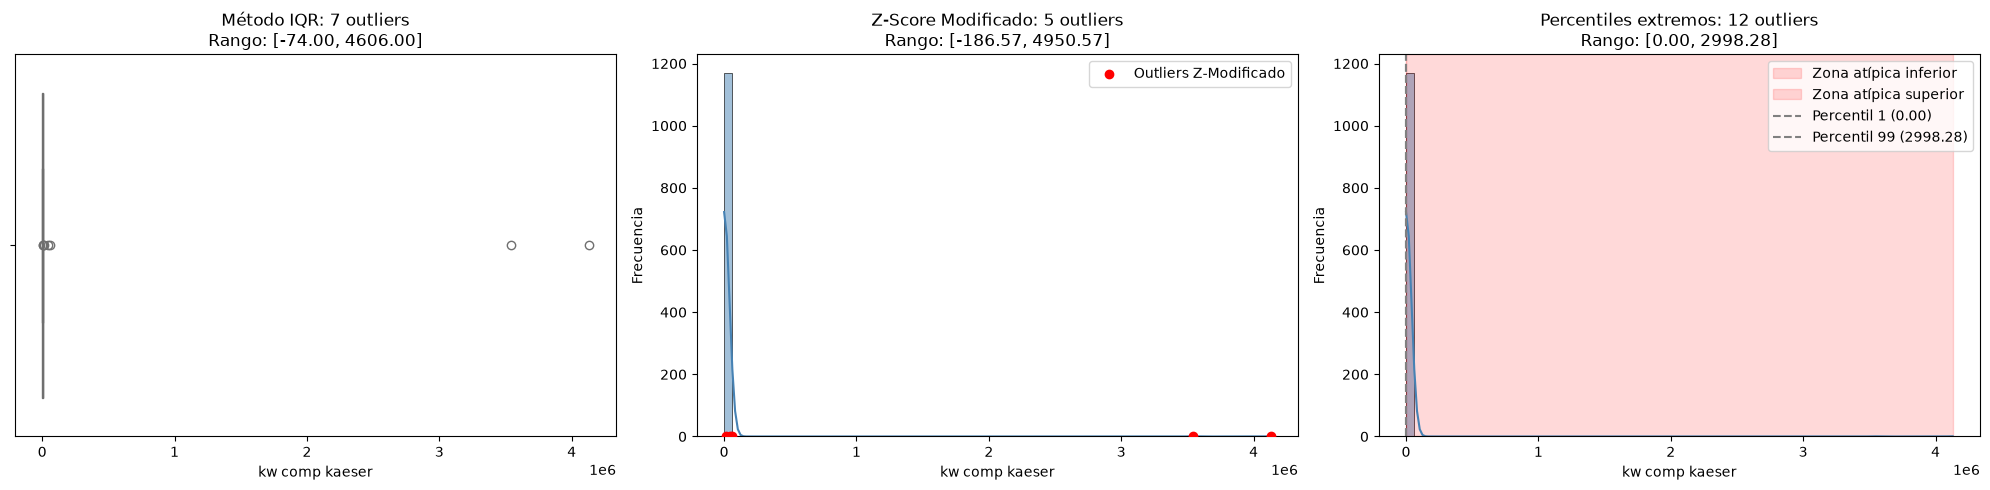

Variable: gas planta (mj)

--- Método IQR ---
Q1: 446519.44 | Q3: 641093.95 | IQR: 194574.51
Rango no atípico: [154657.67, 932955.72]
Cantidad de outliers detectados: 24

--- Método Z-Score Modificado ---
Mediana: 541399.69 | MAD: 97992.3809
Rango no atípico: [32914.39, 1049884.99]
Cantidad de outliers detectados: 3

--- Método Percentiles Extremos ---
Percentil 1: 117677.24 | Percentil 99: 787202.00
Rango no atípico: [117677.24, 787202.00]
Cantidad de outliers detectados: 24


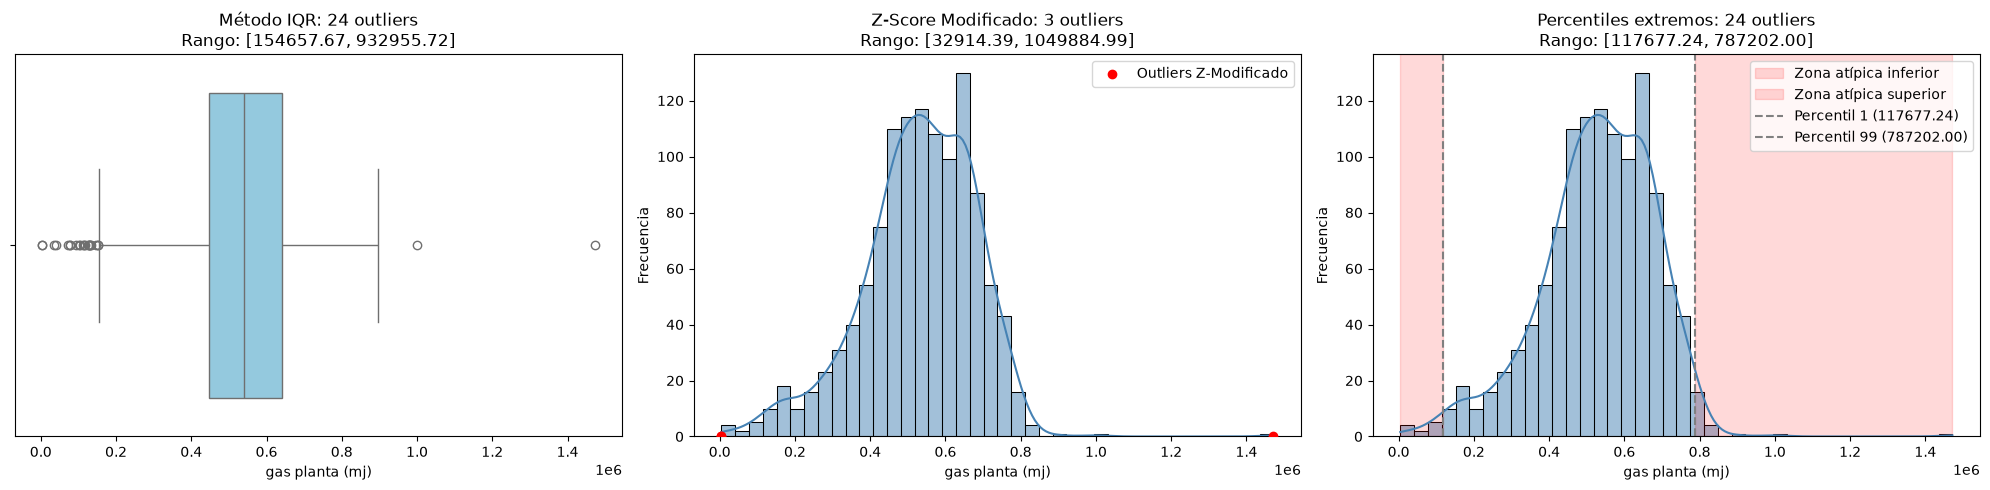

Variable: restos planta (kw)

--- Método IQR ---
Q1: 2477.87 | Q3: 5082.25 | IQR: 2604.38
Rango no atípico: [-1428.70, 8988.82]
Cantidad de outliers detectados: 43

--- Método Z-Score Modificado ---
Mediana: 3575.06 | MAD: 1247.9300
Rango no atípico: [-2900.48, 10050.60]
Cantidad de outliers detectados: 31

--- Método Percentiles Extremos ---
Percentil 1: -1096.78 | Percentil 99: 13201.99
Rango no atípico: [-1096.78, 13201.99]
Cantidad de outliers detectados: 24


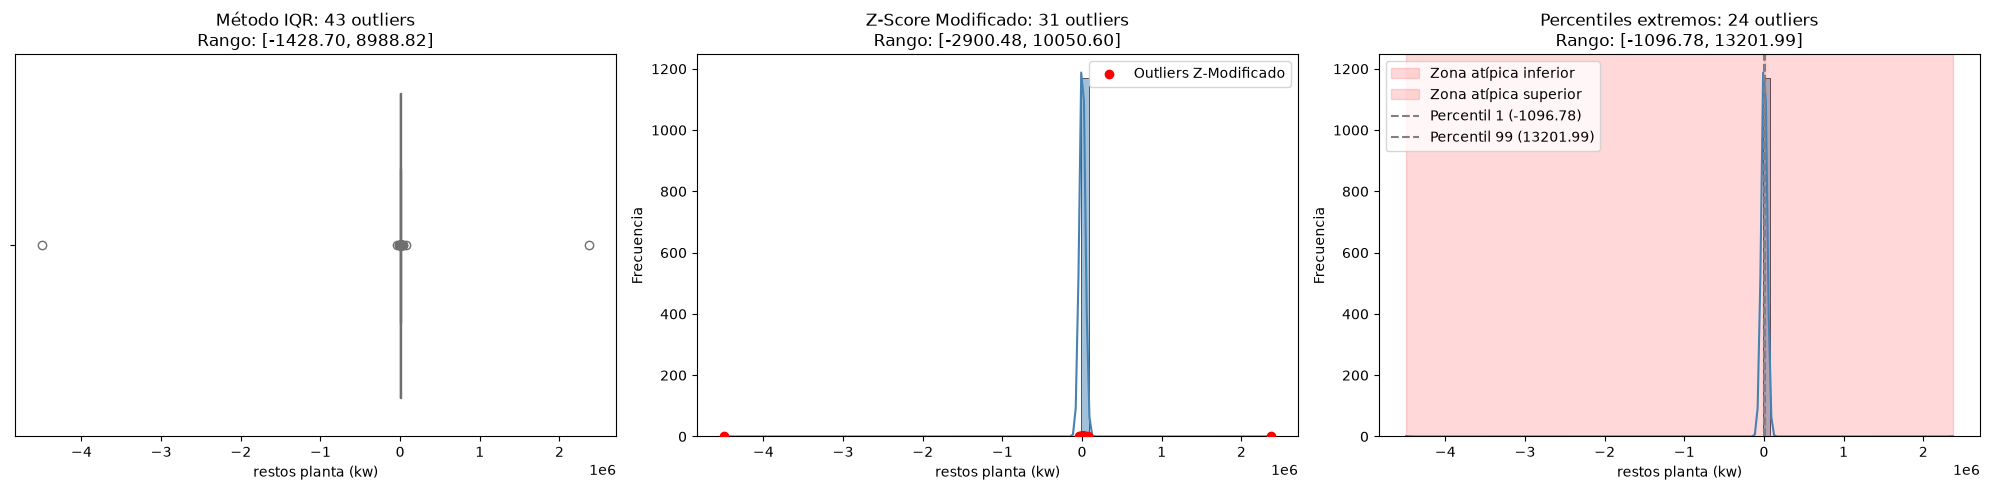

Variable: totalizador bba envasado

--- Método IQR ---
Q1: 1016.31 | Q3: 1848.31 | IQR: 832.00
Rango no atípico: [-231.69, 3096.31]
Cantidad de outliers detectados: 218

--- Método Z-Score Modificado ---
Mediana: 1406.38 | MAD: 408.4400
Rango no atípico: [-713.03, 3525.79]
Cantidad de outliers detectados: 213

--- Método Percentiles Extremos ---
Percentil 1: 0.00 | Percentil 99: 17321.32
Rango no atípico: [0.00, 17321.32]
Cantidad de outliers detectados: 14


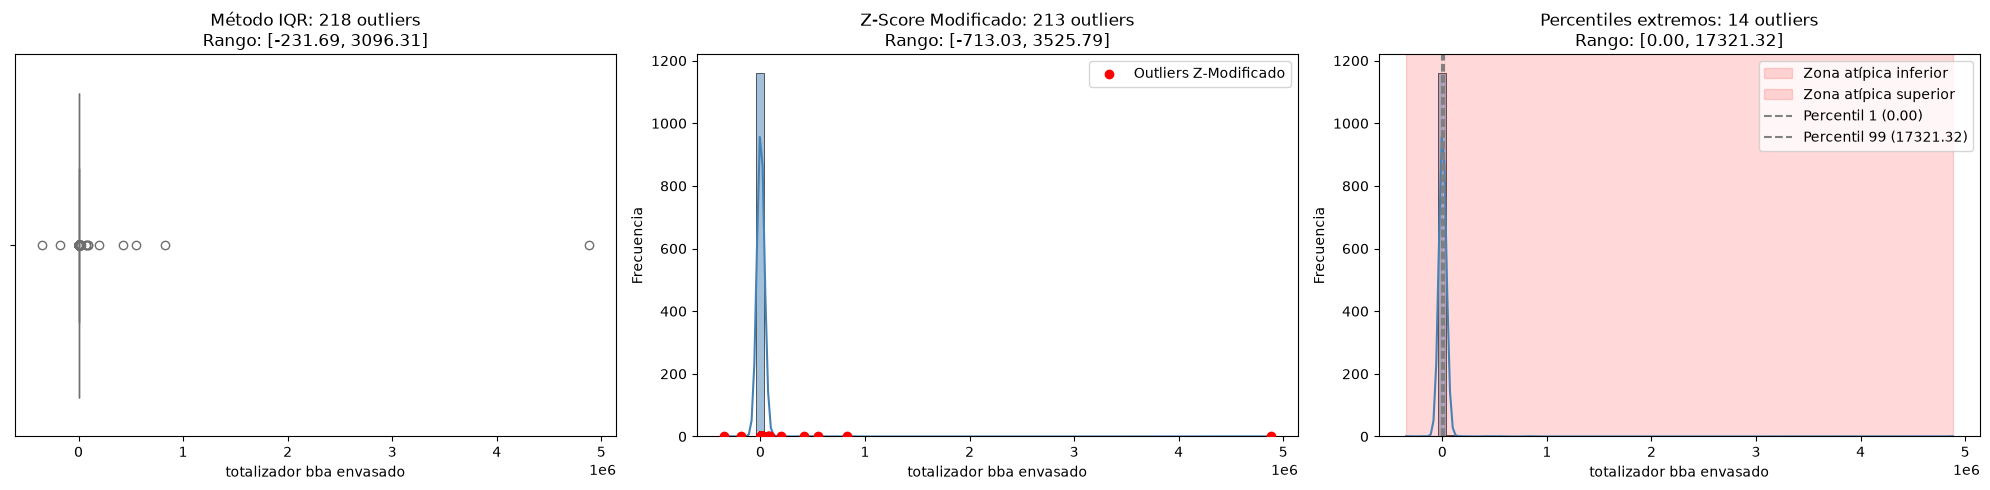

Variable: envasado (kw)

--- Método IQR ---
Q1: 9759.00 | Q3: 19025.00 | IQR: 9266.00
Rango no atípico: [-4140.00, 32924.00]
Cantidad de outliers detectados: 2

--- Método Z-Score Modificado ---
Mediana: 16343.00 | MAD: 3479.0000
Rango no atípico: [-1709.63, 34395.63]
Cantidad de outliers detectados: 2

--- Método Percentiles Extremos ---
Percentil 1: 475.60 | Percentil 99: 21233.88
Rango no atípico: [475.60, 21233.88]
Cantidad de outliers detectados: 24


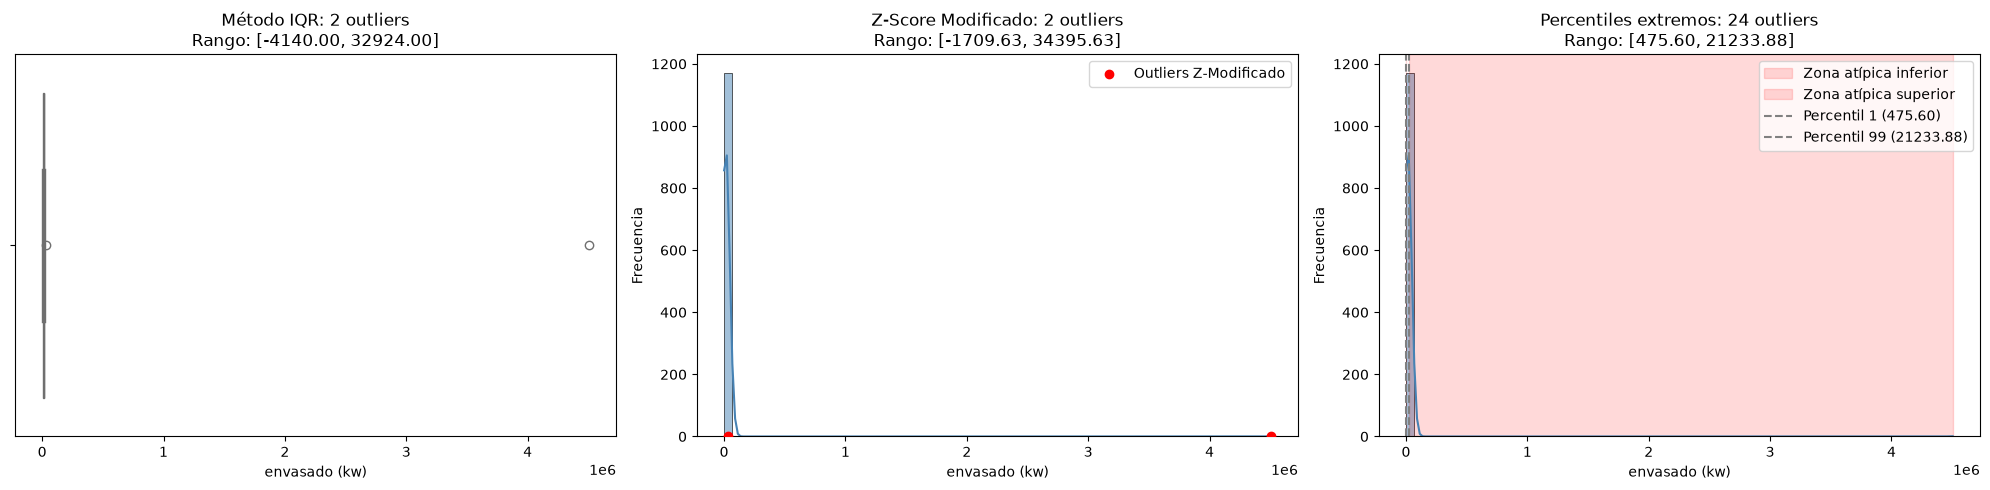

Variable: kw linea 2

--- Método IQR ---
Q1: 604.00 | Q3: 3750.00 | IQR: 3146.00
Rango no atípico: [-4115.00, 8469.00]
Cantidad de outliers detectados: 2

--- Método Z-Score Modificado ---
Mediana: 2795.00 | MAD: 1362.0000
Rango no atípico: [-4272.46, 9862.46]
Cantidad de outliers detectados: 2

--- Método Percentiles Extremos ---
Percentil 1: 0.00 | Percentil 99: 5287.92
Rango no atípico: [0.00, 5287.92]
Cantidad de outliers detectados: 12


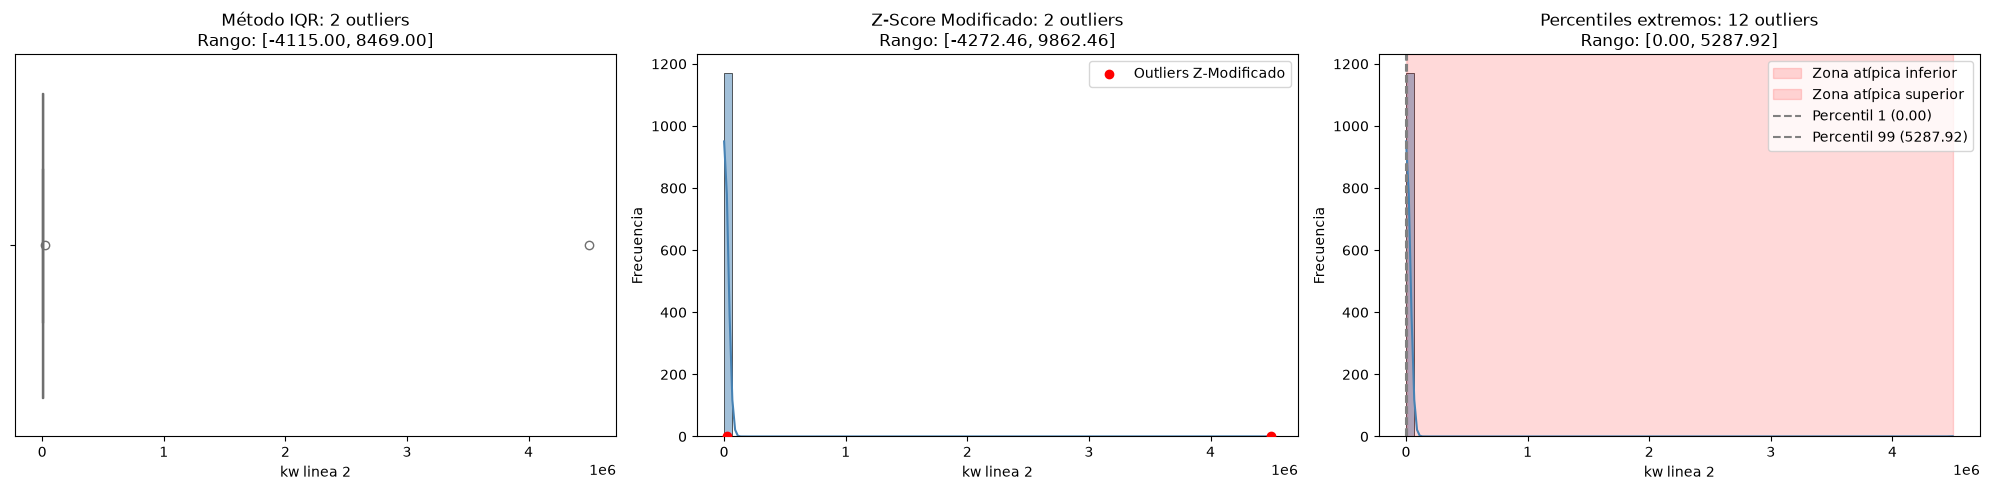

Variable: et envasado (mj)

--- Método IQR ---
Q1: 227806.65 | Q3: 383641.52 | IQR: 155834.87
Rango no atípico: [-5945.65, 617393.83]
Cantidad de outliers detectados: 6

--- Método Z-Score Modificado ---
Mediana: 314025.56 | MAD: 75528.6493
Rango no atípico: [-77894.79, 705945.90]
Cantidad de outliers detectados: 1

--- Método Percentiles Extremos ---
Percentil 1: 16833.55 | Percentil 99: 571669.79
Rango no atípico: [16833.55, 571669.79]
Cantidad de outliers detectados: 24


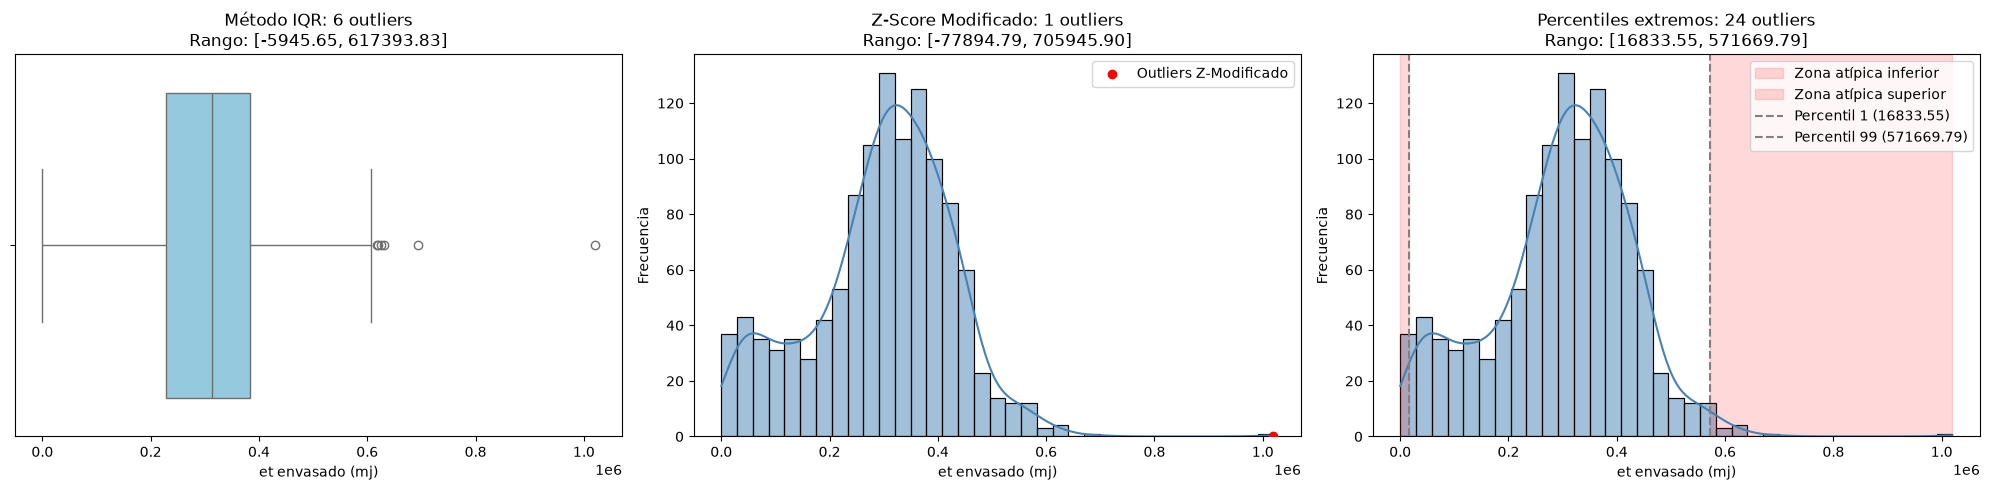

Variable: et elaboracion (mj)

--- Método IQR ---
Q1: 116951.14 | Q3: 244905.44 | IQR: 127954.30
Rango no atípico: [-74980.31, 436836.89]
Cantidad de outliers detectados: 0

--- Método Z-Score Modificado ---
Mediana: 193534.72 | MAD: 59986.2218
Rango no atípico: [-117735.52, 504804.96]
Cantidad de outliers detectados: 0

--- Método Percentiles Extremos ---
Percentil 1: 26965.57 | Percentil 99: 346506.39
Rango no atípico: [26965.57, 346506.39]
Cantidad de outliers detectados: 24


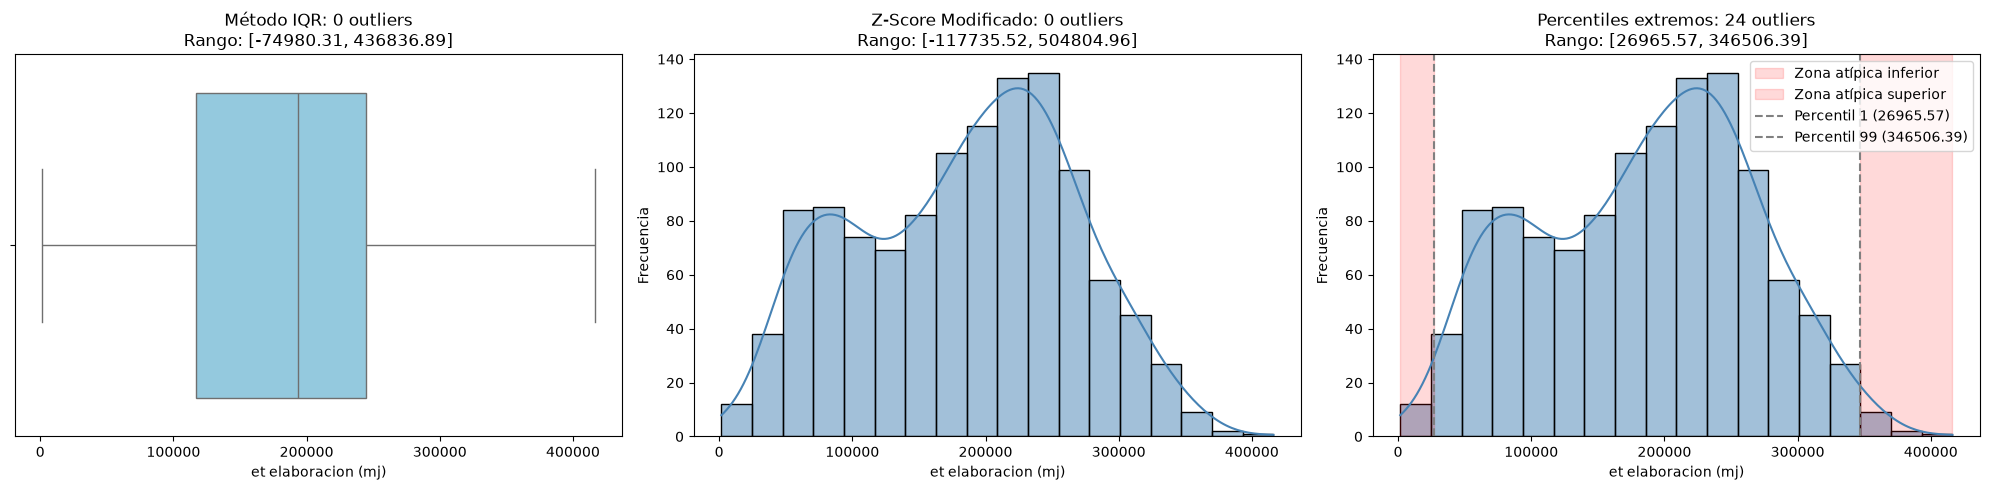

In [ ]:
for n in range(len(features_mayor_varianza)):
    detectar_outliers(df_total, features_mayor_varianza[n])

El método de detección IQR parece ser el que mejor se adapta.

# 1.2

### Evolución del consumo a lo largo del tiempo:

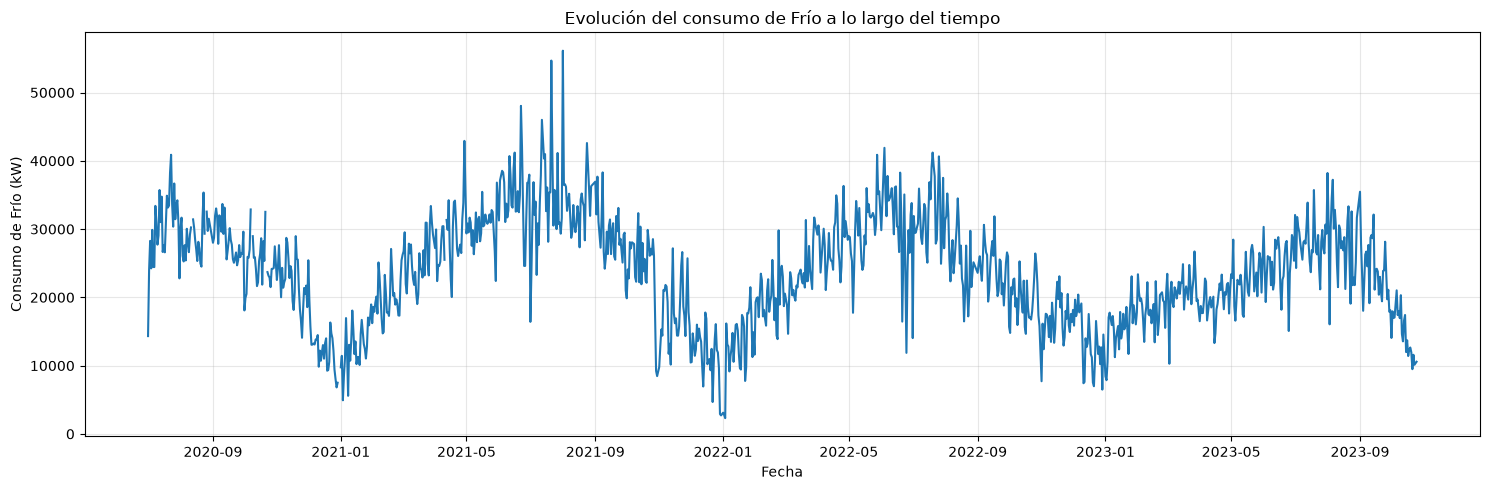

In [ ]:
df_total = df_total.sort_values('fecha')

plt.figure(figsize=(15, 5))
plt.plot(df_total['fecha'], df_total['frio (kw)'])

plt.title('Evolución del consumo de Frío a lo largo del tiempo')
plt.xlabel('Fecha')
plt.ylabel('Consumo de Frío (kW)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

En la época de verano se ve que hay un consumo más elevado.

### Patrones estacionales mensuales y anuales:

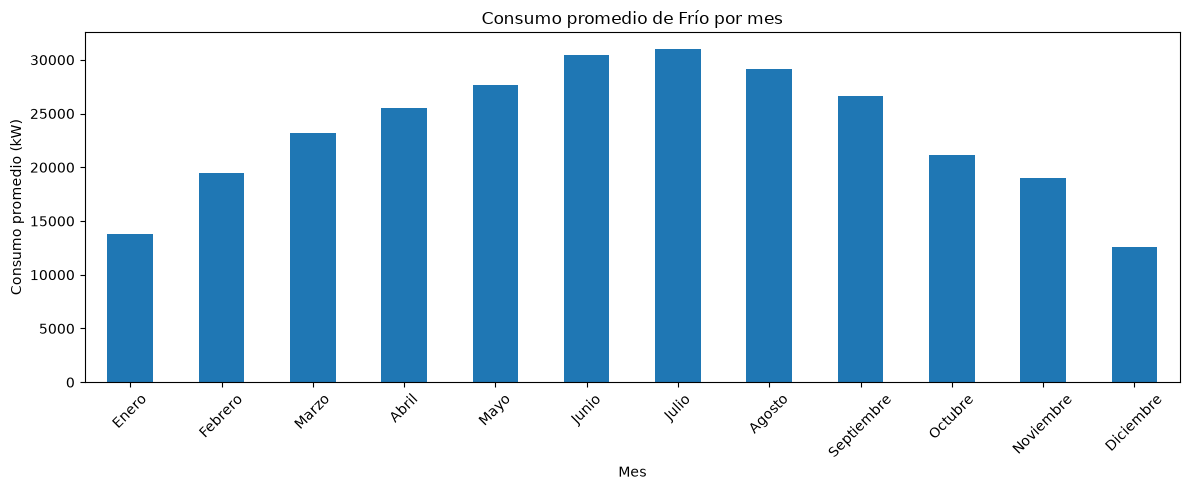

In [ ]:
consumo_mensual = df_total.groupby(
    df_total['fecha'].dt.month
)['frio (kw)'].mean()

meses = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio',
         'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']

consumo_mensual.index = meses

consumo_mensual.plot(kind='bar', figsize=(12, 5))

plt.title('Consumo promedio de Frío por mes')
plt.xlabel('Mes')
plt.ylabel('Consumo promedio (kW)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Podríamos agregar una característica referida al mes.

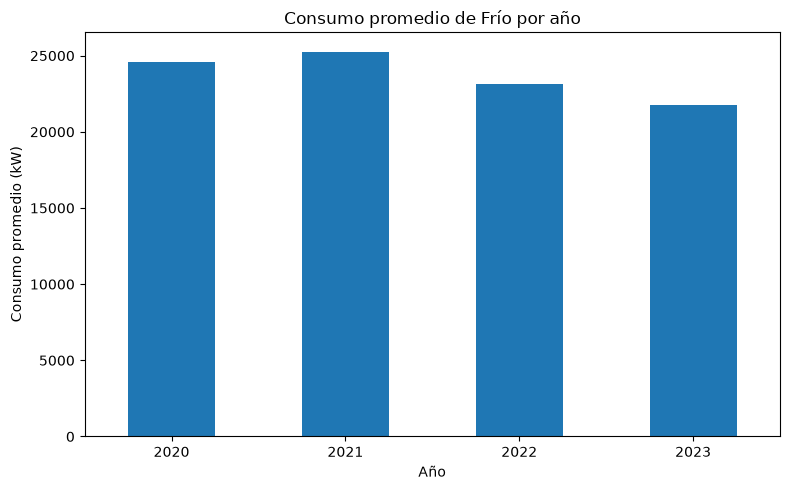

In [ ]:
consumo_anual = df_total.groupby(
    df_total['fecha'].dt.year
)['frio (kw)'].mean()

consumo_anual.plot(kind='bar', figsize=(8, 5))

plt.title('Consumo promedio de Frío por año')
plt.xlabel('Año')
plt.ylabel('Consumo promedio (kW)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Patrones diarios y semanales:

In [107]:
dias = df_total['fecha'].dt.dayofweek

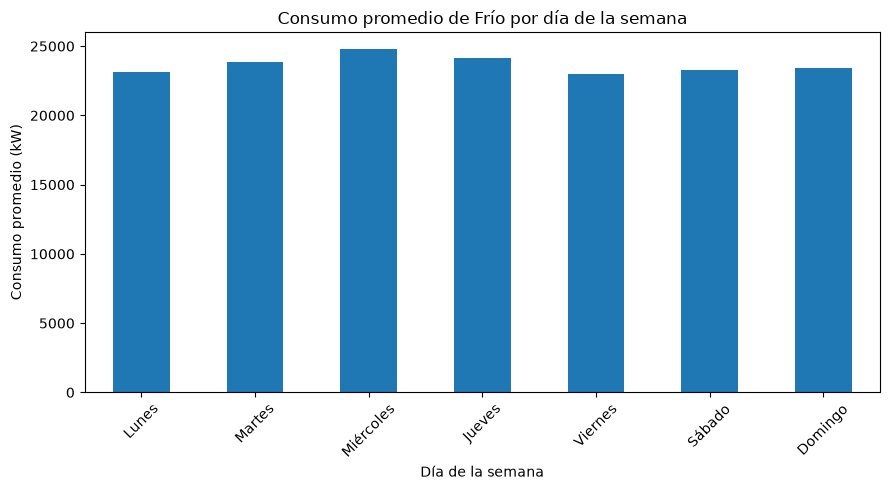

In [108]:
dias = ['Lunes', 'Martes', 'Miércoles', 'Jueves',
        'Viernes', 'Sábado', 'Domingo']

consumo_semanal = df_total.groupby(
    df_total['fecha'].dt.dayofweek
)['frio (kw)'].mean()

consumo_semanal.index = dias

consumo_semanal.plot(kind='bar', figsize=(9, 5))

plt.title('Consumo promedio de Frío por día de la semana')
plt.xlabel('Día de la semana')
plt.ylabel('Consumo promedio (kW)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

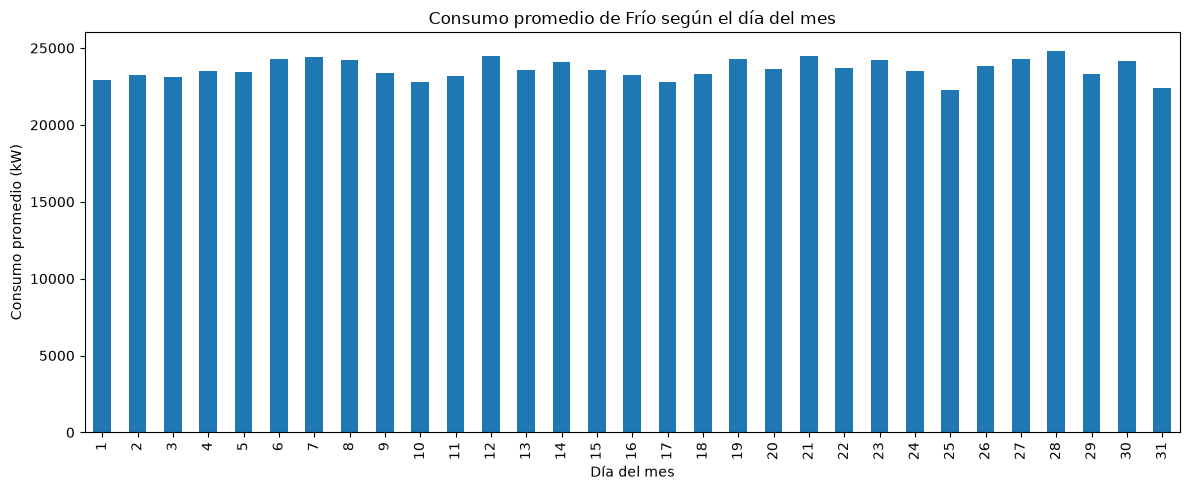

In [109]:
consumo_diario = df_total.groupby(
    df_total['fecha'].dt.day
)['frio (kw)'].mean()

consumo_diario.plot(kind='bar', figsize=(12, 5))

plt.title('Consumo promedio de Frío según el día del mes')
plt.xlabel('Día del mes')
plt.ylabel('Consumo promedio (kW)')
plt.tight_layout()
plt.show()

In [ ]:
grupos = [
    grupo['frio (kw)'].dropna().values
    for _, grupo in df_total.groupby(df_total['fecha'].dt.dayofweek)
]

estadistico, pvalor = f_oneway(*grupos)

print(f"Estadístico F: {estadistico:.4f}")
print(f"Valor p: {pvalor:.6f}")

if pvalor < 0.05:
    print("Hay diferencias significativas entre algunos días.")
else:
    print("No hay evidencia suficiente de diferencias significativas.")

Estadístico F: 1.0998
Valor p: 0.360303
No hay evidencia suficiente de diferencias significativas.


Parece que no aporta mucha información el día de la semana.

In [110]:
from scipy.stats import f_oneway

df_total['dia_mes'] = df_total['fecha'].dt.day

grupos = [
    grupo['frio (kw)'].dropna().values
    for _, grupo in df_total.groupby('dia_mes')
    if len(grupo['frio (kw)'].dropna()) > 0
]

estadistico, pvalor = f_oneway(*grupos)

print(f"Estadístico F: {estadistico:.4f}")
print(f"Valor p: {pvalor:.6f}")

if pvalor < 0.05:
    print("Hay diferencias significativas entre algunos días del mes.")
else:
    print("No hay evidencia suficiente de diferencias significativas.")

Estadístico F: 0.2364
Valor p: 0.999994
No hay evidencia suficiente de diferencias significativas.


Paece que no aporta mucha información el dia del mes.

# 1.3

### Matriz de correlación

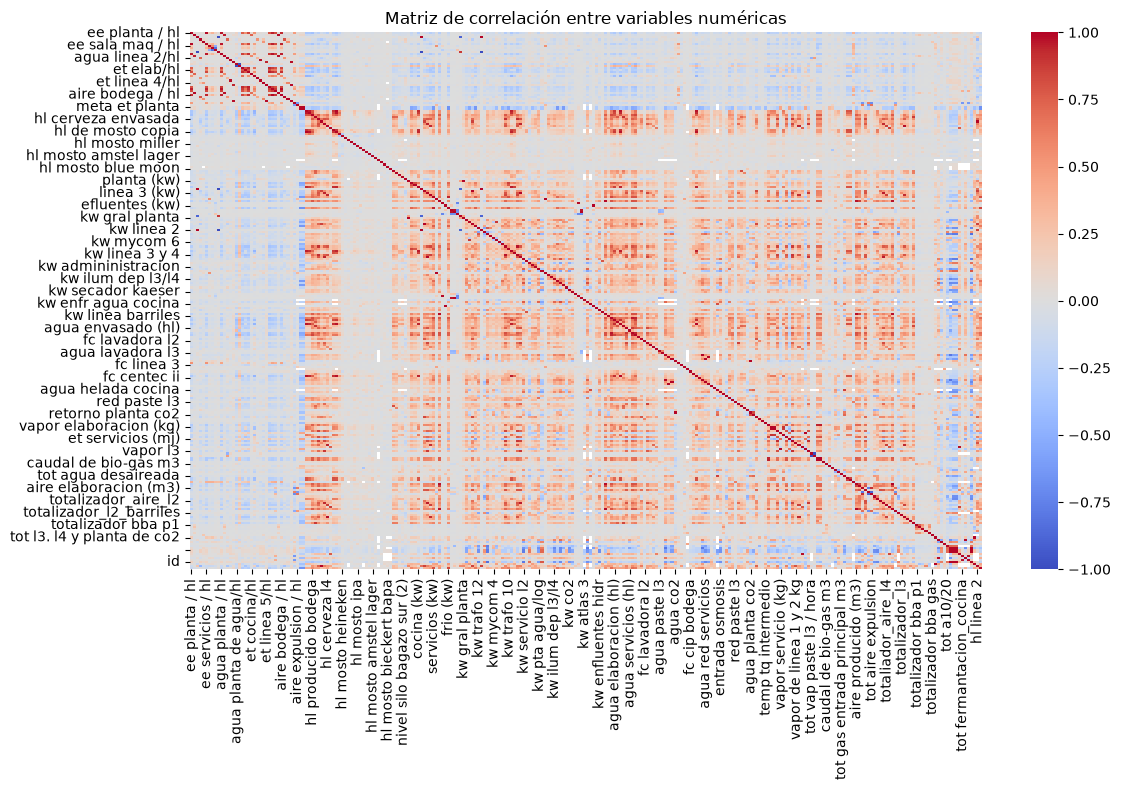

In [33]:
numericas = df_total.select_dtypes(include='number')

correlaciones = numericas.corr(method='pearson')

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlaciones,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Matriz de correlación entre variables numéricas')
plt.tight_layout()
plt.show()

Es complicado analizar por la cantidad de características, al parecer las features medidas por hl (parte arriba izquierda) tienen un comportamiento de correlación elevada. Por otro lado las featues relacionadas a las marcas vemos que no tienen nada de correlación.

### Features más correlacionadas

In [34]:
objetivo = 'frio_mañana (kw)'

correlaciones_target = (
    correlaciones[objetivo]
    .drop(objetivo)
    .dropna()
)

top15 = correlaciones_target.loc[
    correlaciones_target.abs().nlargest(15).index
]

print(top15)

frio (kw)                 0.838512
servicios (kw)            0.809479
agua planta (hl)          0.705823
planta de agua (hl)       0.695988
kw cond 5. 6 y 9          0.667139
produccion (hl)           0.663915
meta et envasado         -0.663892
meta et planta           -0.663892
kw trafo 11               0.646061
kw trafo 10               0.632606
agua cond rec             0.598877
elaboracion (kw)          0.597249
kw mycom 7                0.589894
agua cond evaporativos    0.577736
aire producido (m3)       0.562649
Name: frio_mañana (kw), dtype: float64


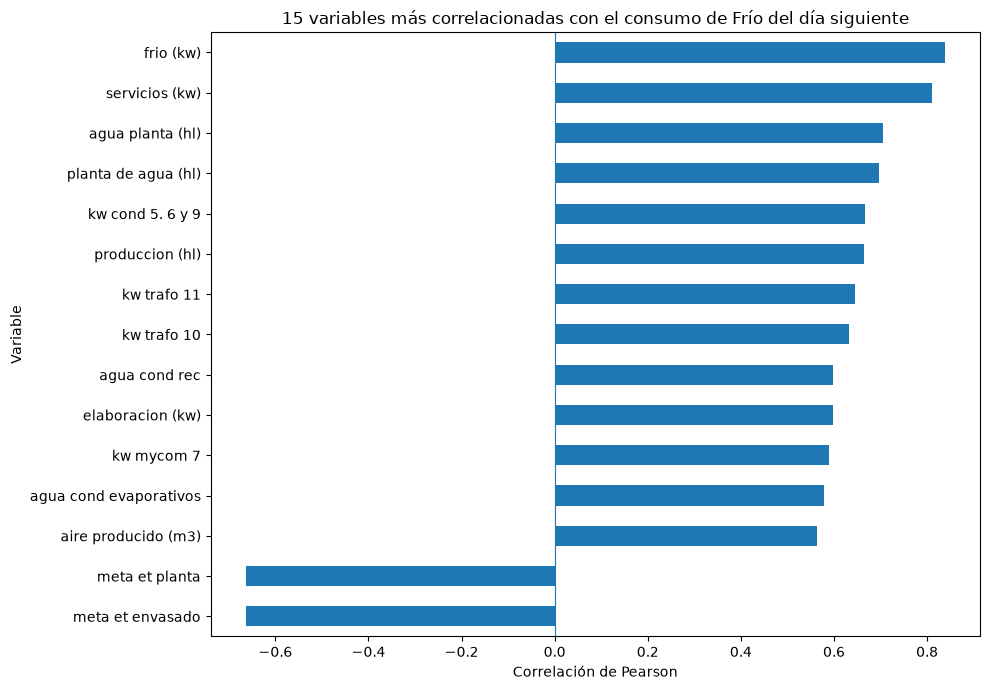

In [35]:
top15_ordenado = top15.sort_values()

plt.figure(figsize=(10, 7))
top15_ordenado.plot(kind='barh')

plt.title('15 variables más correlacionadas con el consumo de Frío del día siguiente')
plt.xlabel('Correlación de Pearson')
plt.ylabel('Variable')
plt.axvline(0, linewidth=0.8)
plt.tight_layout()
plt.show()

In [ ]:
# transformations = []
# transformations.append(f"En las variables de Conglomerado KPI se calculo la mediana los elementos del día y se pusieron como el dato de las 23:59")
# transformations.append(f"Las 15 variables más correlacionadas en este intento: {top15_ordenado.keys()[::-1]}")

# register_version(Path("data/clean/df_total.xlsx"),transformations)

Nueva versión registrada: v4 (5b13813d2b53...)


Se puede ver por ejemplo en las metas et (enegía térmica) al ser mayores disminuye el frío de mañana, esto tiene sentido ya que al tener como meta temperaturas más elevadas se va a requerir que se gaste menos energía en enfriar.

### Multicolinealidad entre predictores

In [121]:
predictores = numericas.drop(columns=[objetivo], errors='ignore')

corr_predictores = predictores.corr().abs()

# Evitar pares duplicados y correlaciones de una variable consigo misma
mascara = np.triu(
    np.ones(corr_predictores.shape, dtype=bool),
    k=1
)

pares = (
    corr_predictores.where(mascara)
    .stack()
    .sort_values(ascending=False)
)

pares_fuertes = pares[pares > 0.8]

print("Pares de predictores con correlación absoluta > 0.8:")
print(pares_fuertes)

Pares de predictores con correlación absoluta > 0.8:
agua efluentes                   agua red servicios               1.000000
medicion gas planta (m3)         m3_tot_gas                       1.000000
hl de mosto                      hl de mosto copia                1.000000
agua calderas                    agua cald                        1.000000
agua cocina (hl)                 fc cocina                        1.000000
aire producido (m3)              totalizador sistema kaeser       1.000000
meta et planta                   meta et envasado                 1.000000
tot l3. l4 y planta de co2       tot l3, l4 y planta de co2       1.000000
vapor servicio (kg)              tot_vapor_cip_bodega             1.000000
agua planta de agua/hl           produccion agua / hl             1.000000
agua cond evaporativos           agua cond rec                    1.000000
unnamed: 3                                                        1.000000
                                 .1            

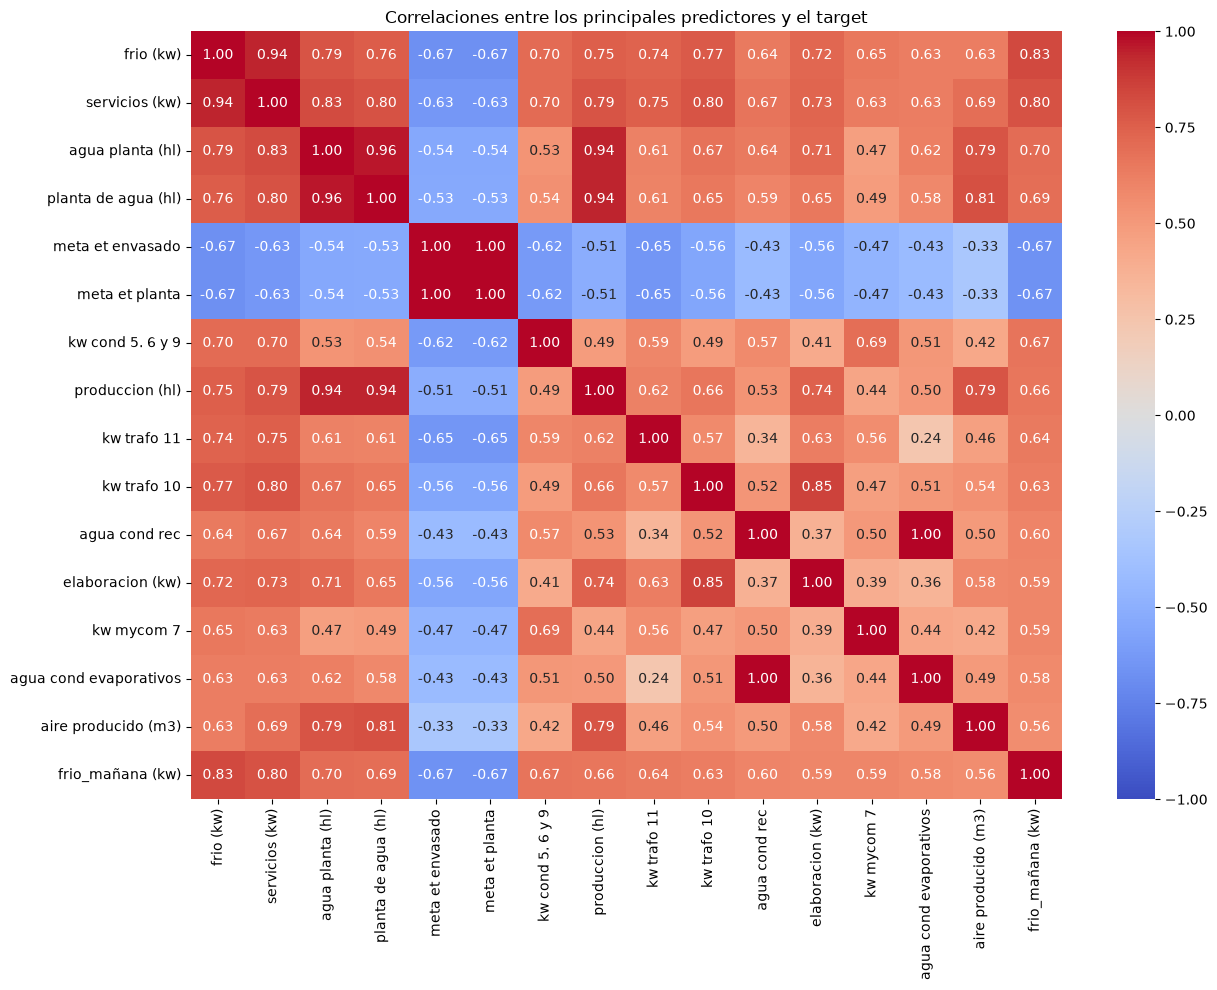

In [122]:
columnas_heatmap = top15.index.tolist() + [objetivo]

corr_top15 = df_total[columnas_heatmap].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(
    corr_top15,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1
)

plt.title('Correlaciones entre los principales predictores y el target')
plt.tight_layout()
plt.show()

Hay varios pares de variables que están muy correlacionados, se podría utilizar esto para selección de variables.

# 1.4

### Boxplots mensuales para identificar estacionalidad

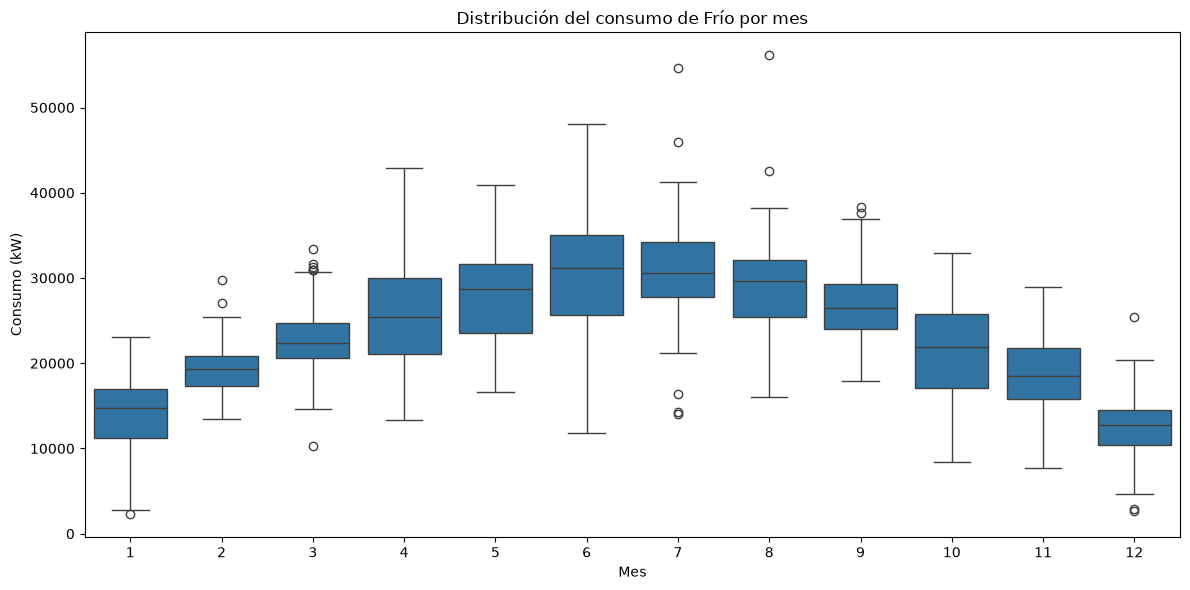

In [124]:
df_total['mes'] = df_total['fecha'].dt.month

plt.figure(figsize=(12, 6))

sns.boxplot(data=df_total, x='mes', y='frio (kw)')

plt.title('Distribución del consumo de Frío por mes')
plt.xlabel('Mes')
plt.ylabel('Consumo (kW)')
plt.tight_layout()
plt.show()

Se puede apreciar que el consumo aumenta hasta junio-julio, luego vuelve a disminuir. Tiene sentido ya que en verano al haber temperaturas más elevadas se requiere gastar más energía en enfriar, igualmente junio presenta mucha varianza y julio outliers, estos podrían ser veranos en los que hubo niveles de temperatura por debajo y por encima de lo normal.

### Distribución del target (histograma y QQ-plot)

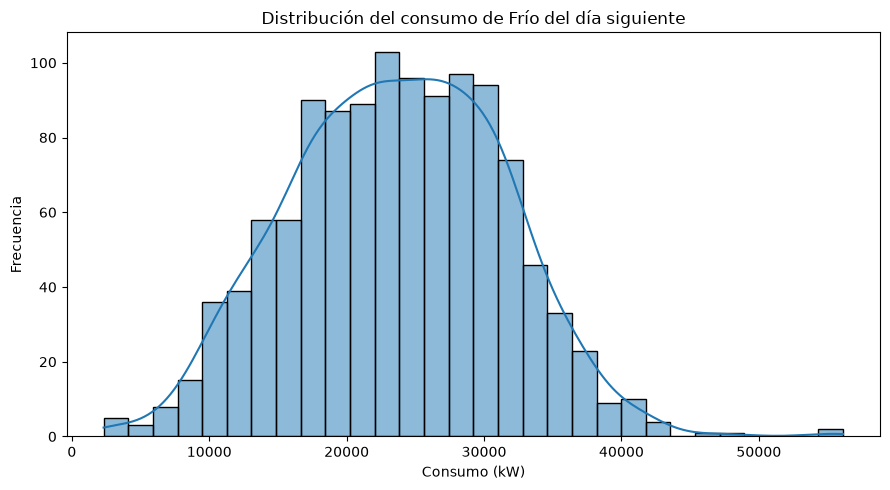

In [125]:
target = df_total['frio_mañana (kw)'].dropna()

plt.figure(figsize=(9, 5))

sns.histplot(target, bins=30, kde=True)

plt.title('Distribución del consumo de Frío del día siguiente')
plt.xlabel('Consumo (kW)')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

Los valores cercanos a 50000 podrían tratarse de valores cercanos a la media los cuales no se reinicio el totalizador y se tomó la medición de dos días o una situación similar.

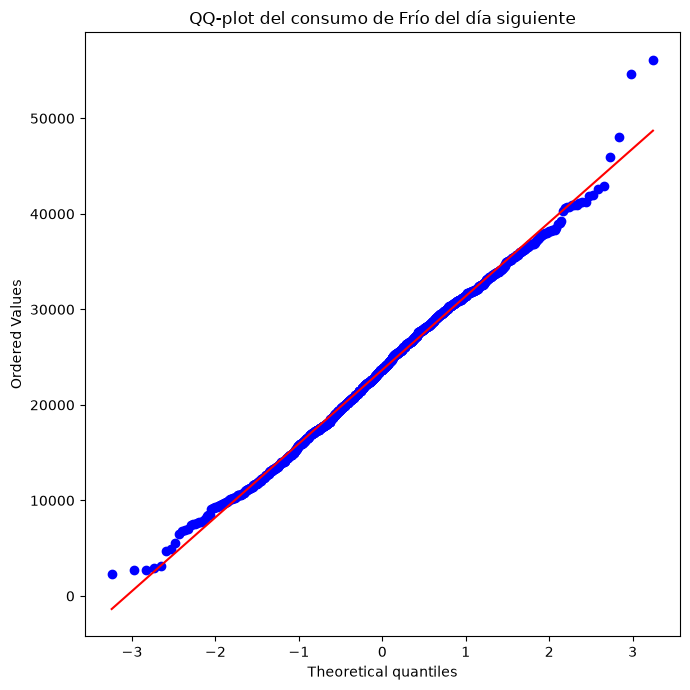

In [126]:
from scipy import stats

plt.figure(figsize=(7, 7))

stats.probplot(target, dist='norm', plot=plt)

plt.title('QQ-plot del consumo de Frío del día siguiente')
plt.tight_layout()
plt.show()

Pareciera que la variable objetivo sigue una distribución medianamente normal, siendo afectada en los extremos.

### Scatter plots de las 5 variables más correlacionadas vs. target

In [127]:
objetivo = 'frio_mañana (kw)'

numericas = df_total.select_dtypes(include='number')

correlaciones = numericas.corr()[objetivo].drop(objetivo).dropna()

top5 = correlaciones.abs().nlargest(5).index

print('Cinco variables más correlacionadas:')
print(correlaciones.loc[top5])

Cinco variables más correlacionadas:
frio (kw)              0.834334
servicios (kw)         0.804177
agua planta (hl)       0.700968
planta de agua (hl)    0.691815
meta et envasado      -0.667848
Name: frio_mañana (kw), dtype: float64


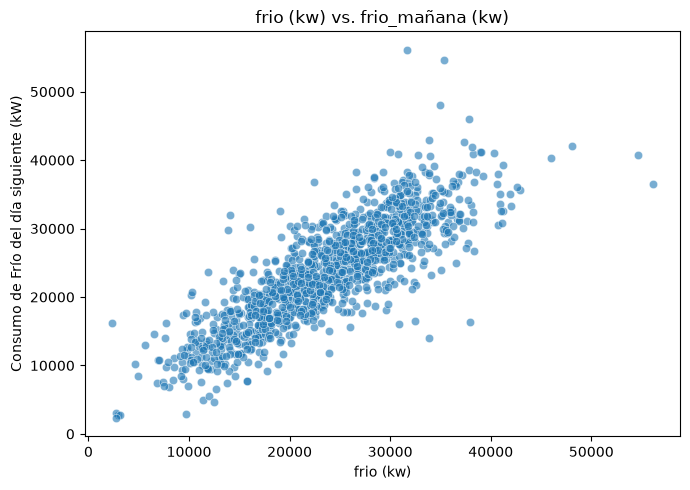

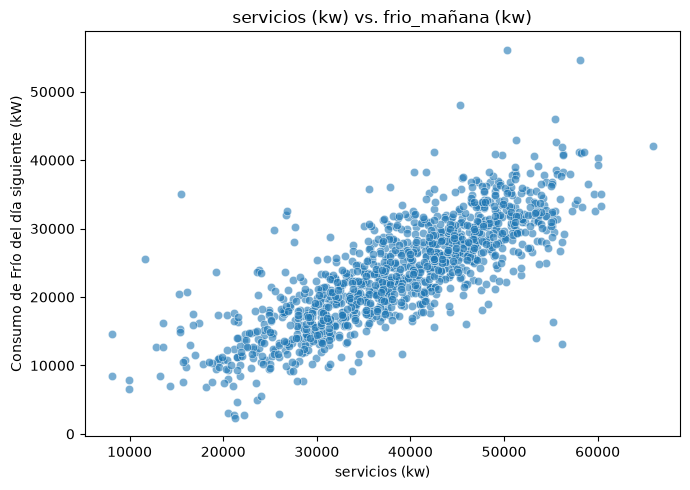

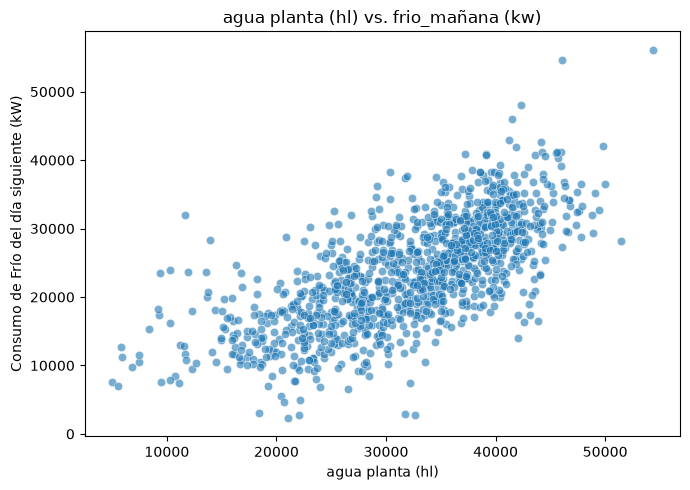

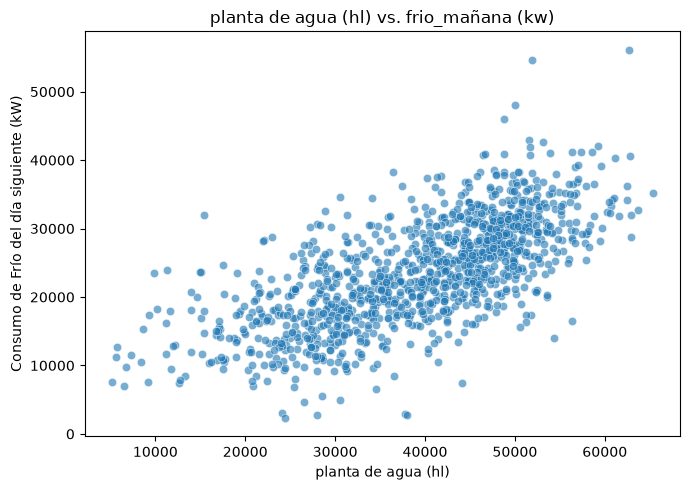

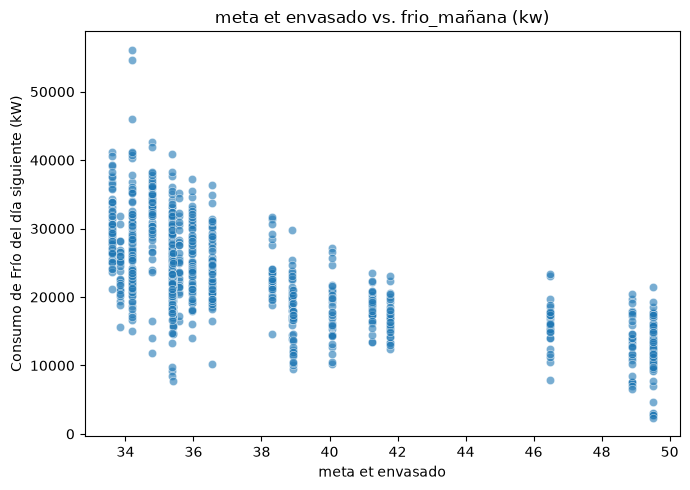

In [128]:
for variable in top5:
    datos = df_total[[variable, objetivo]].dropna()

    plt.figure(figsize=(7, 5))

    sns.scatterplot(data=datos, x=variable, y=objetivo, alpha=0.6)

    plt.title(f'{variable} vs. {objetivo}')
    plt.xlabel(variable)
    plt.ylabel('Consumo de Frío del día siguiente (kW)')
    plt.tight_layout()
    plt.show()

### Análisis de consumo por área de la planta (Elaboración, Envasado, etc.)

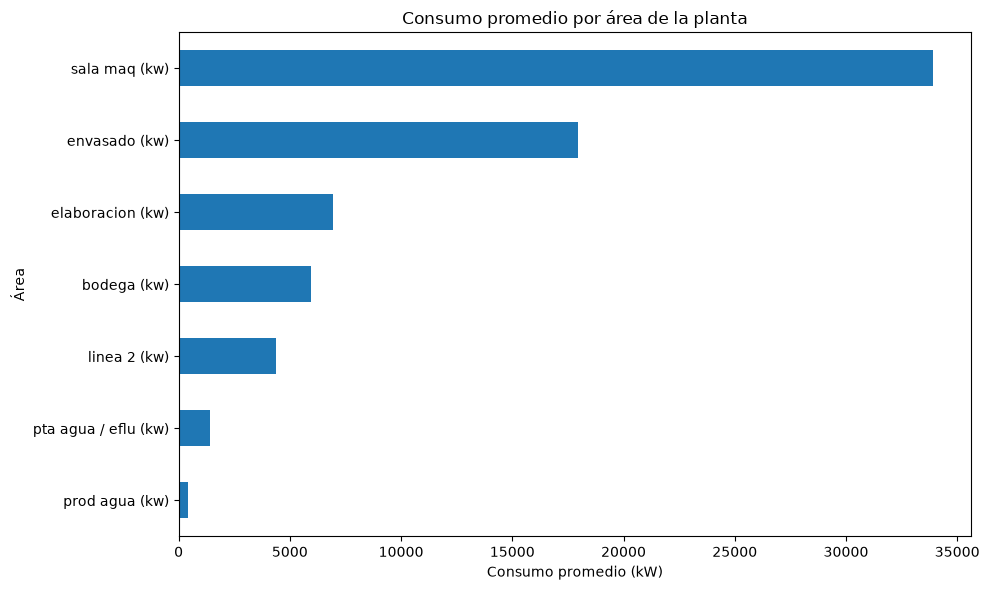

In [129]:
areas = [
    'elaboracion (kw)',
    'bodega (kw)',
    'envasado (kw)',
    'linea 2 (kw)',
    'sala maq (kw)',
    'pta agua / eflu (kw)',
    'prod agua (kw)'
]

areas_disponibles = [col for col in areas if col in df_total.columns]

consumo_areas = df_total[areas_disponibles].mean().sort_values()

plt.figure(figsize=(10, 6))

consumo_areas.plot(kind='barh')

plt.title('Consumo promedio por área de la planta')
plt.xlabel('Consumo promedio (kW)')
plt.ylabel('Área')
plt.tight_layout()
plt.show()